need to normalise peak flux of each emmission to x-ray flux

honestly just need the peak flux value of both and thats it 


for flares that occur right on the hour need both hours for peak flux in differeent sectrums 

# Part 1
## Flare locating with properties


In [1]:
import sunpy
import sunpy.timeseries 
from sunpy.net import Fido, attrs as a
import matplotlib.pyplot as plt
import sunpy.map
import numpy as np

/Users/scottd/miniforge3/envs/sunpy-clean/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



with this I can find the data of the flares:
location on sun, 
magnitude (awful rounding, compared to space weather live),
time (time seemas a bit iffy comparing peak and end times) 



In [13]:
tstart = '2010/05/01 07:23:56'
tend = '2011/04/11 12:40:29'
event_type = 'FL'
min_flare_class = "M1.0"
result = Fido.search(
    a.Time(tstart,tend), 
    a.hek.EventType(event_type),
    a.hek.FL.GOESCls >= min_flare_class,
)
print(len(result[0]))

99


In [19]:
hek_results = result["hek"]

start_times=[]
end_times=[]
peak_time=[]
mag_class=[]
hgs_x_coord=[]
hgs_y_coord=[]

year1=1
month1=1
day1=1
hour1=1
for i, flare in enumerate(hek_results):


    t=flare['event_starttime']
    year=int(t.ymdhms.year)
    month=int(t.ymdhms.month)
    day=int(t.ymdhms.day)
    hour=int(t.ymdhms.hour)
    if year1==year and month1==month and day1==day and hour1==hour:    ####### fucks up 2 or more flares in one hour bin
        pass
    else:
        peak_time.append(flare['event_peaktime'])
        start_times.append(flare['event_starttime'])
        end_times.append(flare['event_endtime'])
        
        mag_class.append(flare['fl_goescls'])
        hgs_x_coord.append(flare['hgs_x'])
        hgs_y_coord.append(flare['hgs_y'])

    
    year1=year
    month1=month
    day1=day
    hour1=hour

    
    flag=0
    if flag==1:
        print(f"Flare {i}")
        print(f"GOES class: {flare['fl_goescls']}")
        print(f"Start time:  {flare['event_starttime']}")
        print(f"Peak time:  {flare['event_peaktime']}")
        print(f"End time:  {flare['event_endtime']}")
        print(f"HeliographicStonyhurst longitude: {flare['hgs_x']}")
        print(f"HeliographicStonyhurst latitude: {flare['hgs_y']}")
        #print(f"SkyCoord:   {flare['event_coord']}")
        print("-" * 40)
radi=np.sqrt((np.array(hgs_x_coord)**2)+(np.array(hgs_y_coord)**2))

# Part 2
## Flare emission download 


In [33]:
##remote python download
import webbrowser
from pathlib import Path
from urllib.request import urlretrieve

from astropy.io import fits
from datetime import date
import time

### will want to change download location before proper start

In [44]:
x1=0
x2=2
files=[]
XRS_files=[]
for i in range(len(peak_time)):
    
    # Example: 2014-01-01, 00:00–01:00 UTC
    t=peak_time[i]
    year=int(t.ymdhms.year)
    month=int(t.ymdhms.month)
    day=int(t.ymdhms.day)
    hour=int(t.ymdhms.hour)
    day_of_year = date(year, month, day).timetuple().tm_yday
    
    version = 8
    revision = 1
    
    prefix = "EVL"  # EVL = lines; EVS = spectra
    filename = (f"{prefix}_L2_{year}{day_of_year:03d}_{hour:02d}_"
        f"{version:03d}_{revision:02d}.fit.gz")
    
    x1=filename
    if x1==x2:
        continue
    x2=x1
    
    url = ("https://lasp.colorado.edu/eve/data_access/"
        f"evewebdata/products/level2/{year}/{day_of_year:03d}/{filename}")
    #webbrowser.open(url)
    files.append(filename)
    print(filename)

    flag=1                   # xray part
    if flag==1:
        
        result = Fido.search(a.Time(f'{year}-{month}-{day} {hour}:00', f'{year}-{month}-{day} {hour}:01'), a.Instrument("XRS"),  a.Resolution("flx1s"))
        XRay_file = Fido.fetch(result, path='./GOES_XRS_Data/')
        XRS_files.append(XRay_file[0])
        print(XRay_file[0])

    #time.sleep(0.2)# 0.2 second pause for each download

    #break # to not download a ton by accident 
with open('EVL_L2_files/EVEfiles.txt', 'w') as f:
    for line in files:
        f.write(f"{line}\n")

with open('GOES_XRS_Data/XRSfiles.txt', 'w') as f:
    for line in XRS_files:
        f.write(f"{line}\n")

EVL_L2_2010125_17_008_01.fit.gz


Files Downloaded: 100%|██████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  1.94file/s]


GOES_XRS_Data/sci_gxrs-l2-irrad_g14_d20100505_v0-1-0.nc
EVL_L2_2010163_00_008_01.fit.gz


Files Downloaded: 100%|██████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  1.97file/s]


GOES_XRS_Data/sci_gxrs-l2-irrad_g14_d20100612_v0-1-0.nc
EVL_L2_2010164_05_008_01.fit.gz


Files Downloaded: 100%|██████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  1.98file/s]


... (77 outputs left out)

Files Downloaded: 100%|██████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  1.97file/s]


GOES_XRS_Data/sci_gxrs-l2-irrad_g15_d20110324_v0-1-0.nc
EVL_L2_2011084_23_008_01.fit.gz


Files Downloaded: 100%|██████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  2.01file/s]

GOES_XRS_Data/sci_gxrs-l2-irrad_g15_d20110325_v0-1-0.nc


In [49]:
with open('EVL_L2_files/EVEfiles.txt') as f:
    filename = f.read().splitlines()
print(len(filename))
with open('GOES_XRS_Data/XRSfiles.txt') as f:
    Xrayfilename = f.read().splitlines()
print(len(Xrayfilename))

43
43


# Part 3
## Flare emission line processing


In [2]:
from astropy.io import fits
from astropy.time import Time
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime, timedelta
from pathlib import Path
from astropy.visualization import time_support

from sunpy import timeseries as ts

In [11]:
#file_list=[str(x.resolve()) for x in Path('EVL_L2_files').glob('*.fit.gz')]
#file_list.sort()
#file_XRS_list=[str(x.resolve()) for x in Path('GOES_XRS_Data').glob('*v0-1-0.nc')]
#file_XRS_list.sort()

In [11]:
with open('EVL_L2_files/EVEfiles.txt') as f:
    filename = f.read().splitlines()
print(len(filename))
with open('GOES_XRS_Data/XRSfiles.txt') as f:
    Xrayfilename = f.read().splitlines()
print(len(Xrayfilename))

43
43


In [12]:
print(len(peak_time))

45


2010-05-05 17:19:00.000


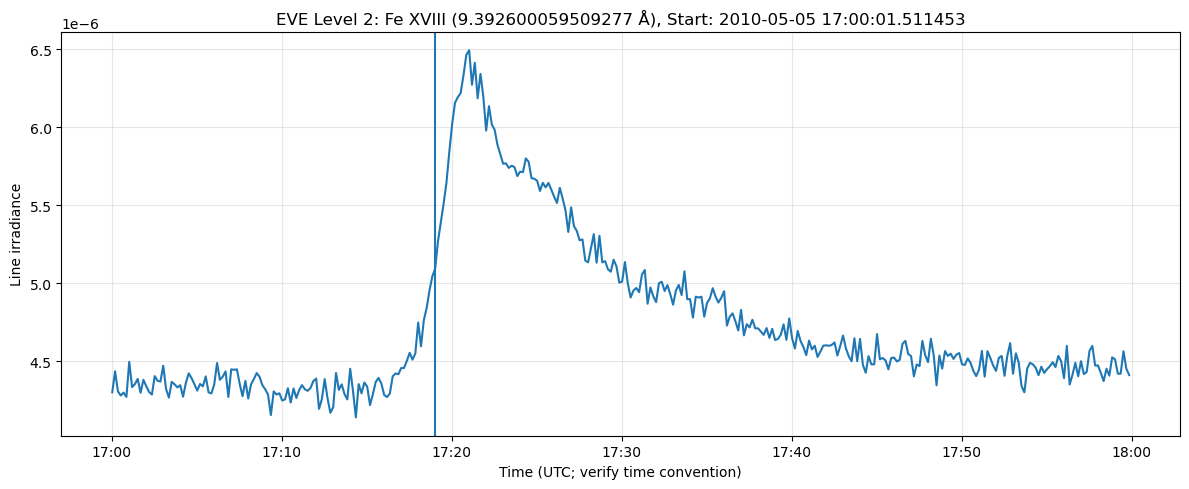

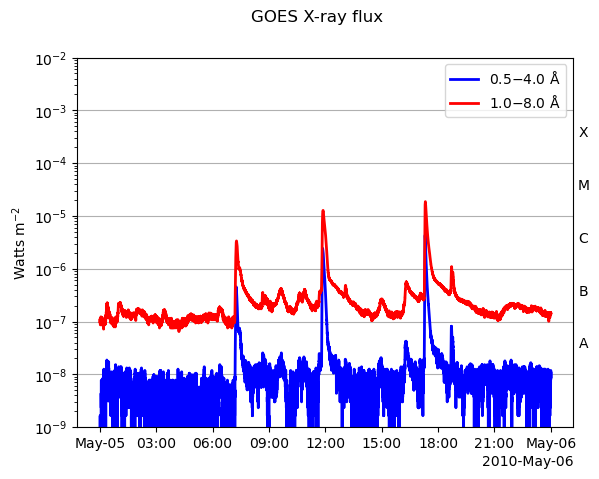

2010-06-12 00:57:00.000


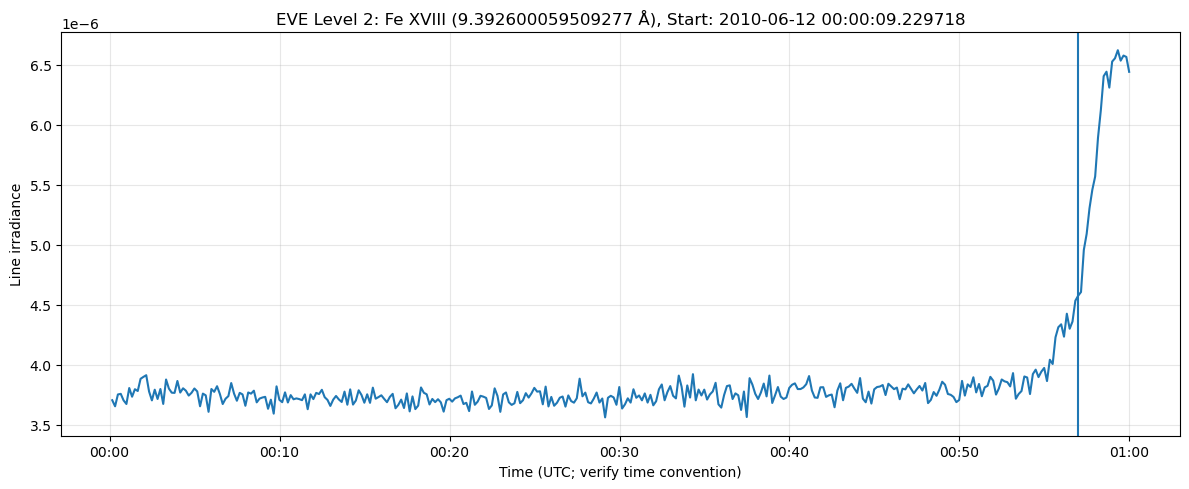

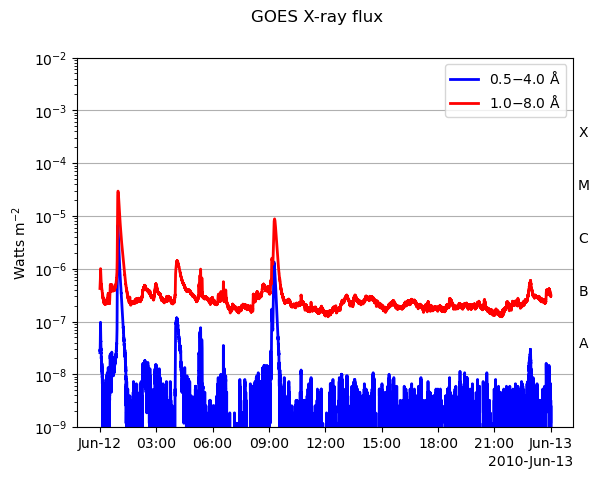

2010-06-13 05:39:00.000


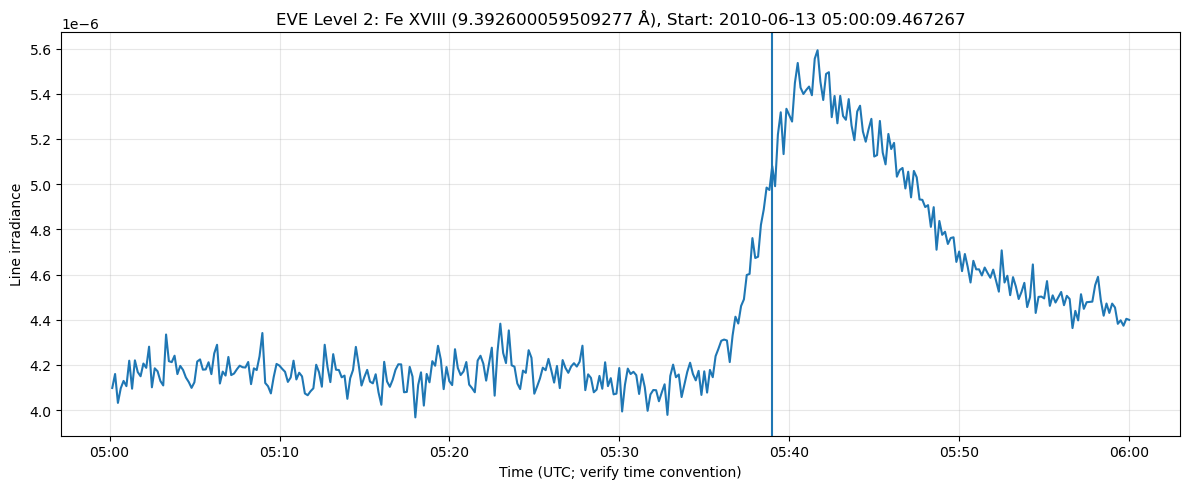

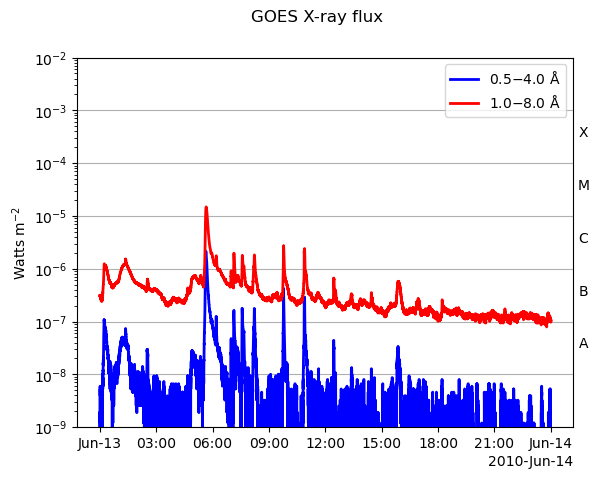

2010-08-07 18:24:00.000


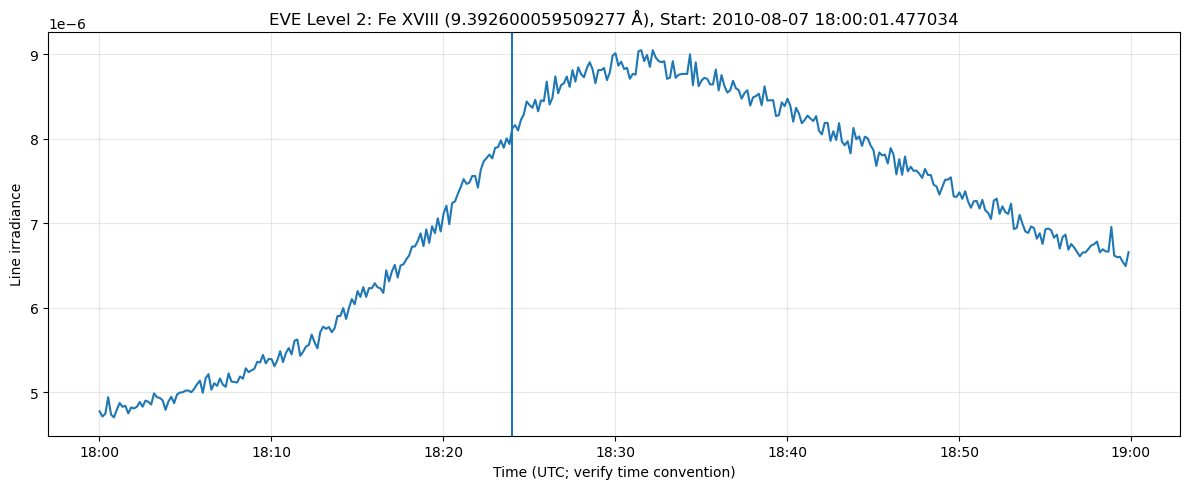

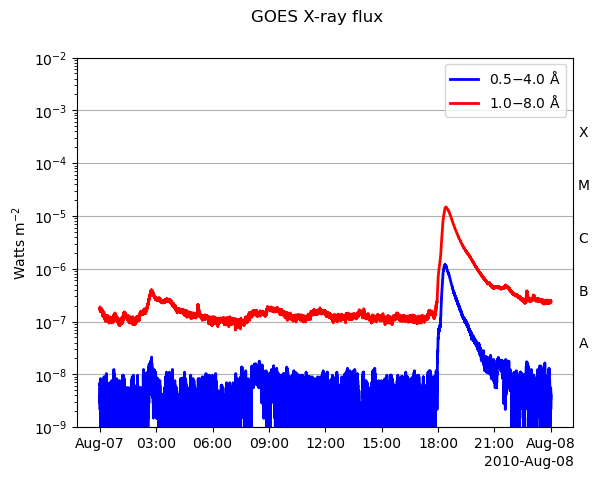

2010-10-16 19:12:00.000


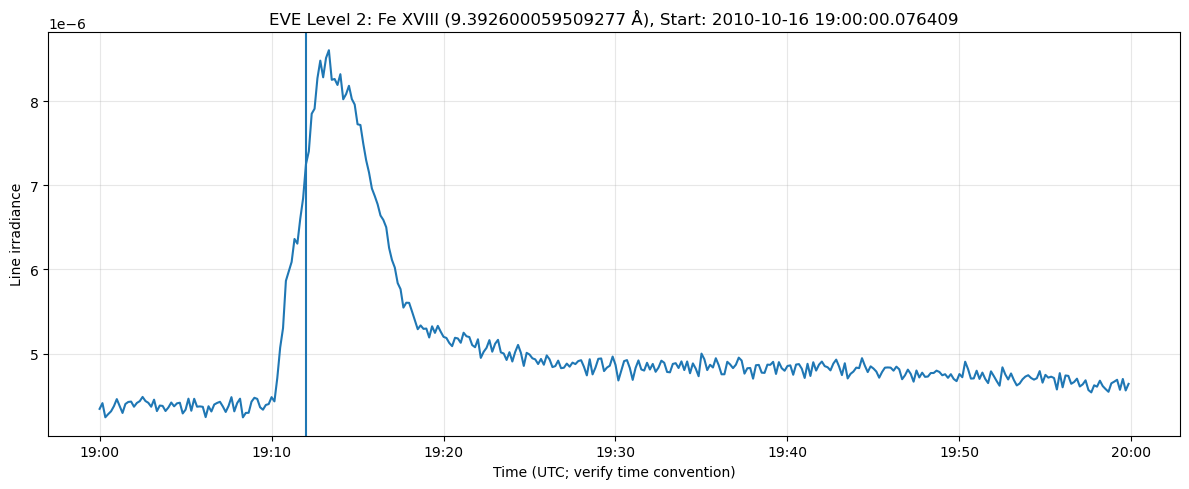

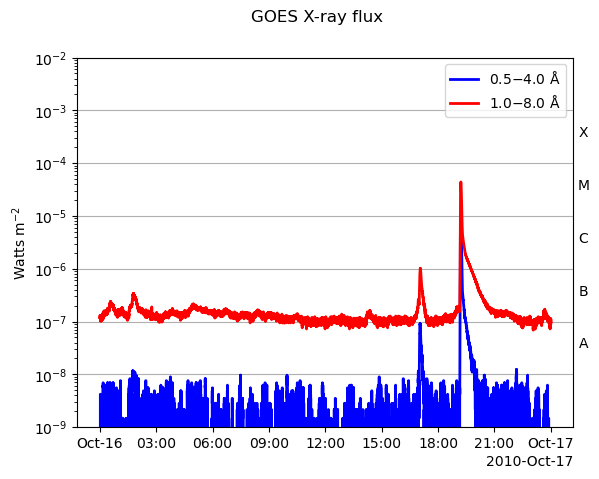

2010-11-04 23:58:00.000


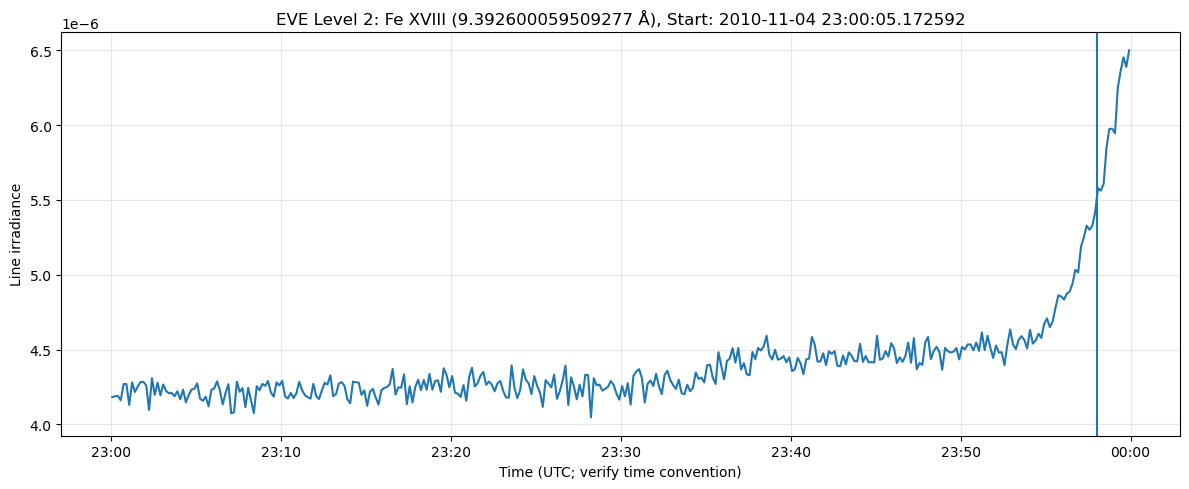

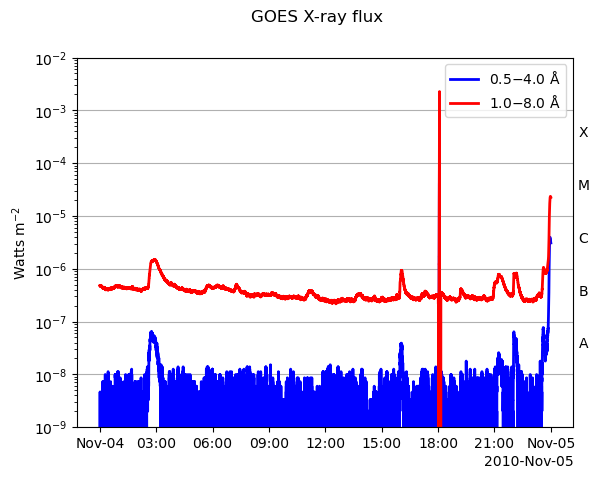

2010-11-05 13:29:00.000


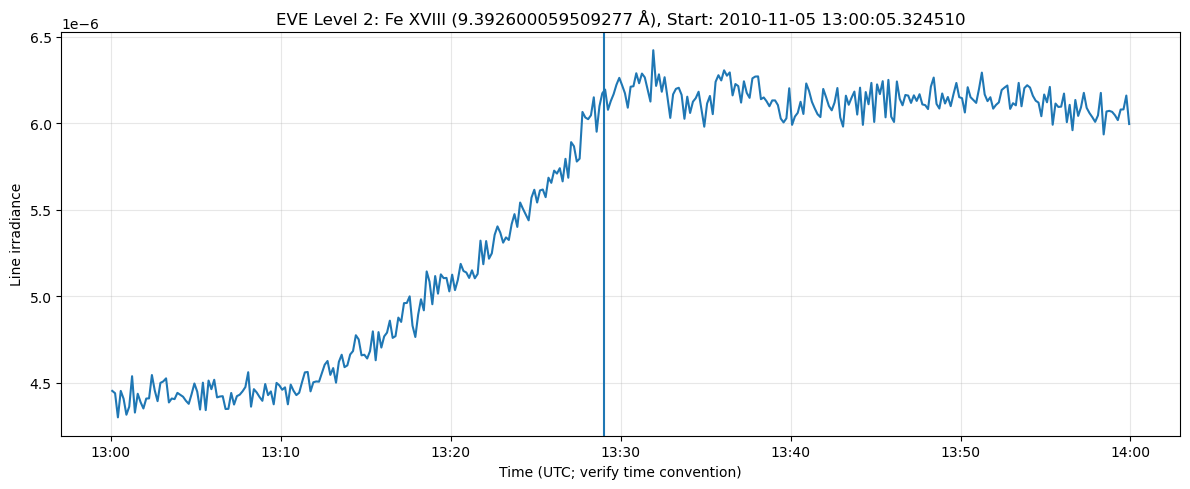

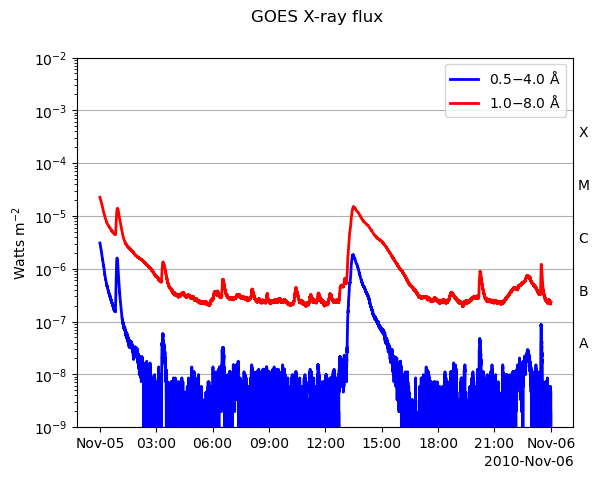

2010-11-06 15:36:00.000


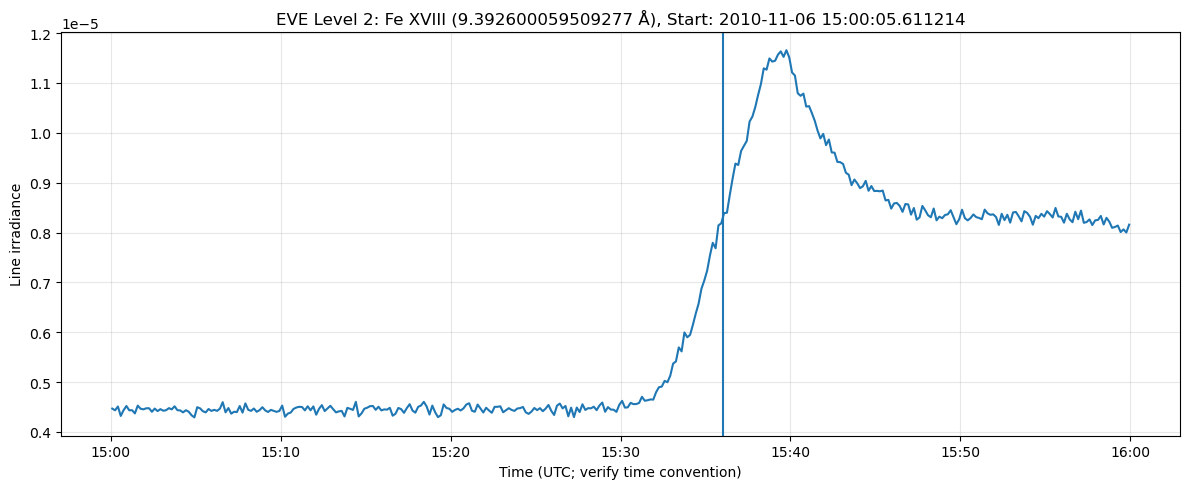

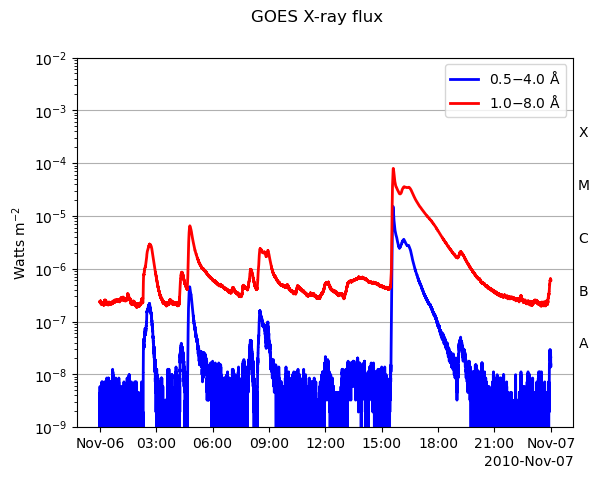

2011-01-28 01:03:00.000


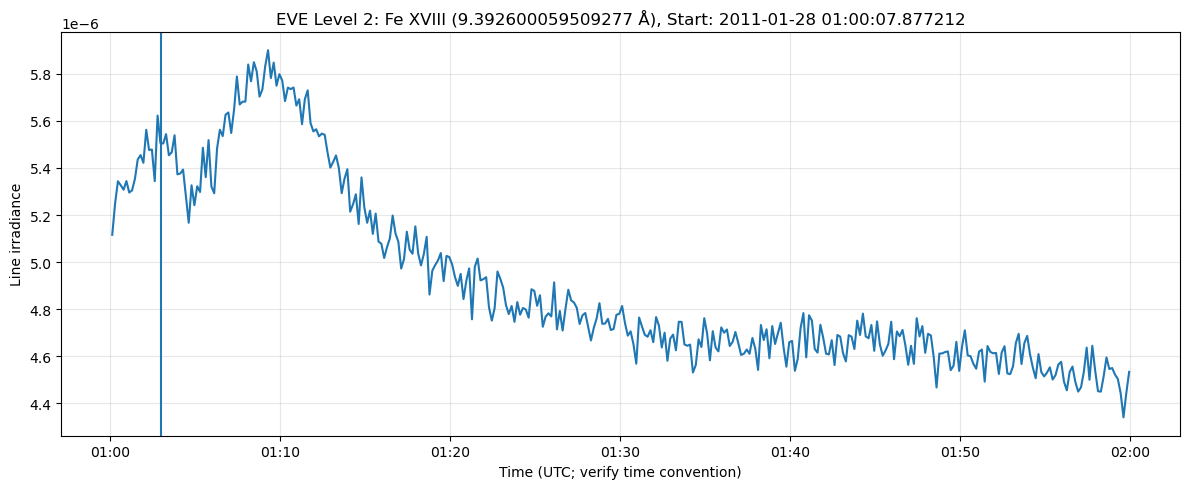

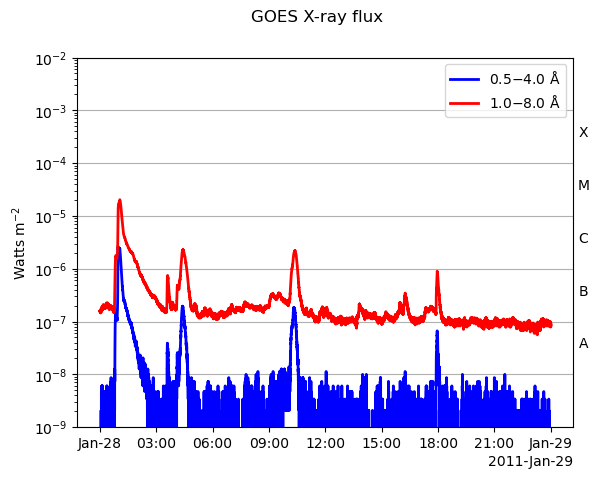

2011-02-09 01:28:00.000


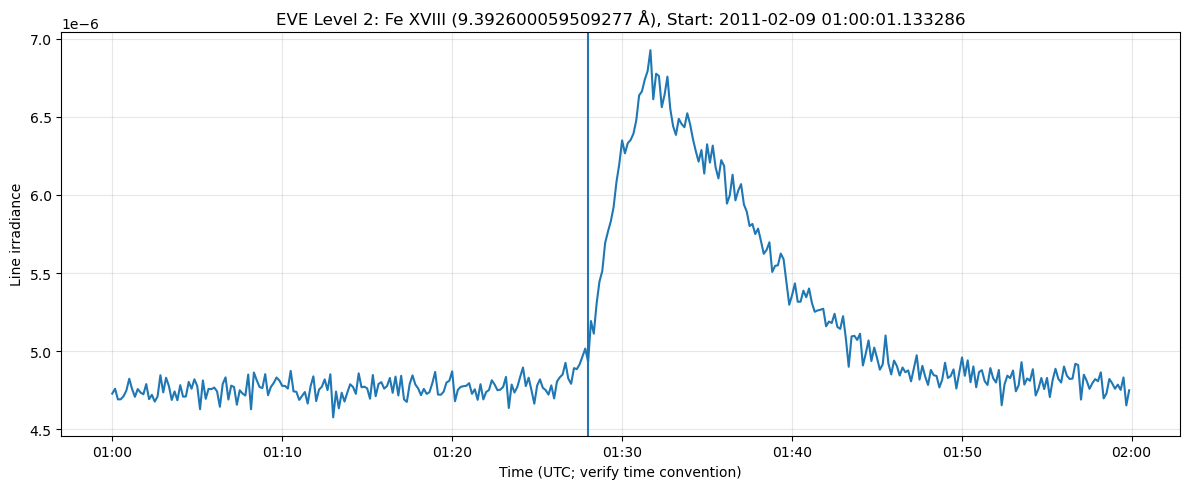

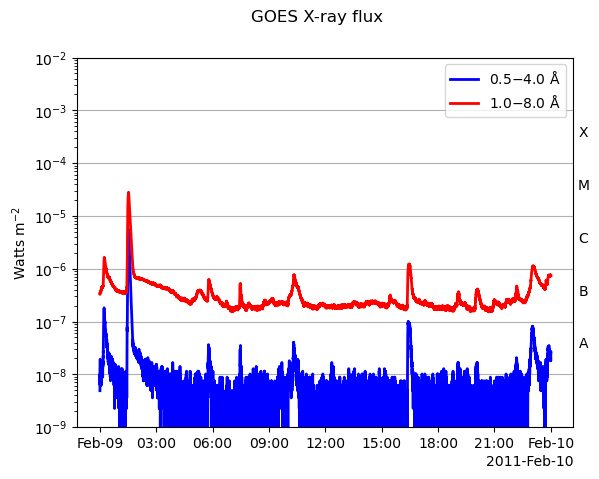

2011-02-13 17:30:00.000


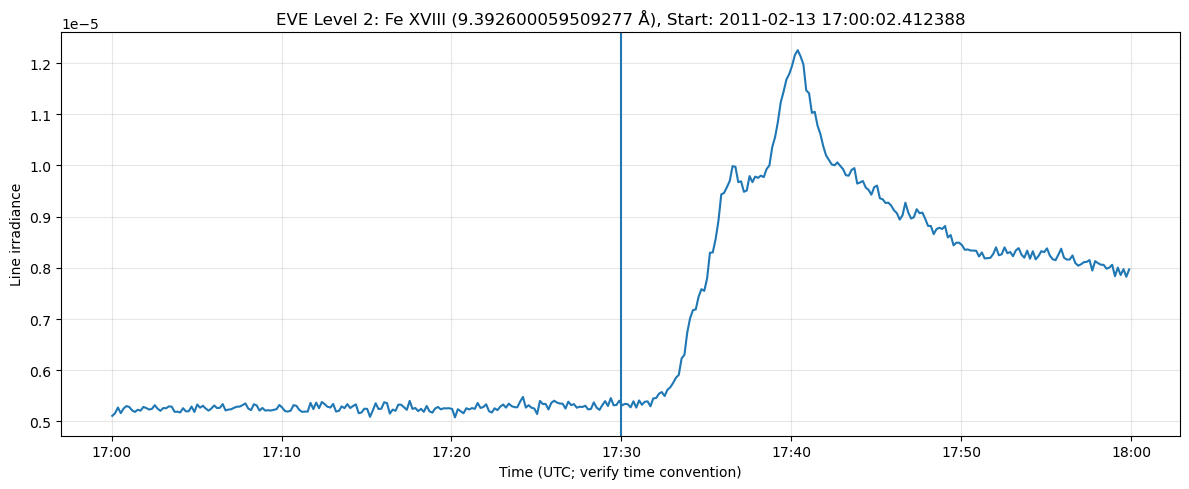

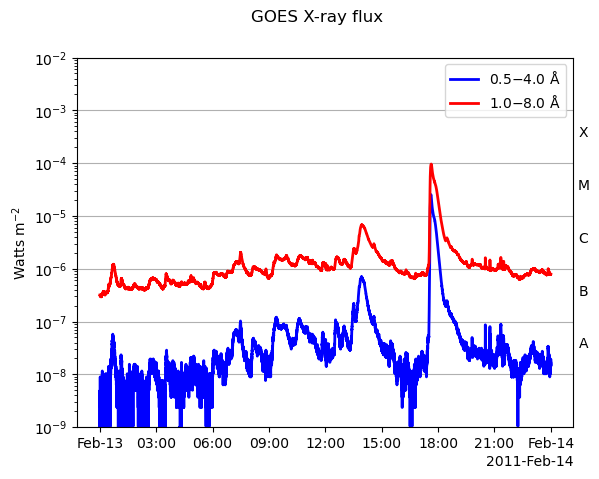

2011-02-14 17:26:00.000


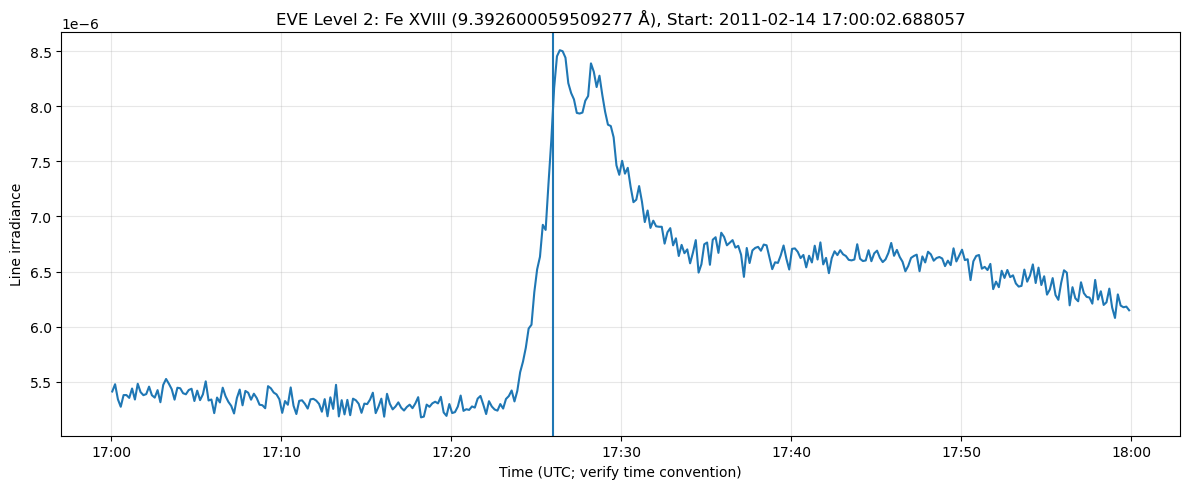

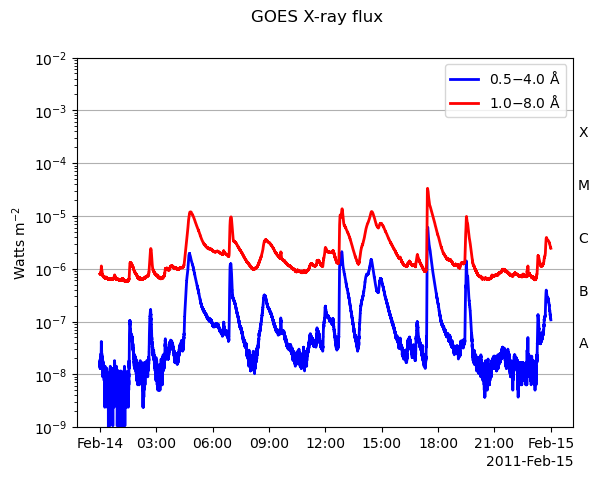

2011-02-15 01:45:00.000


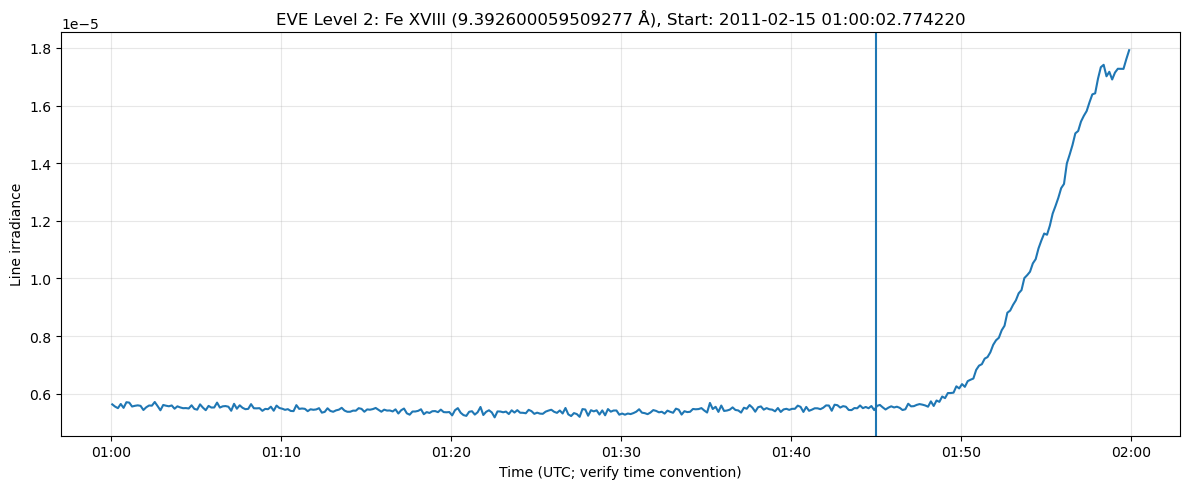

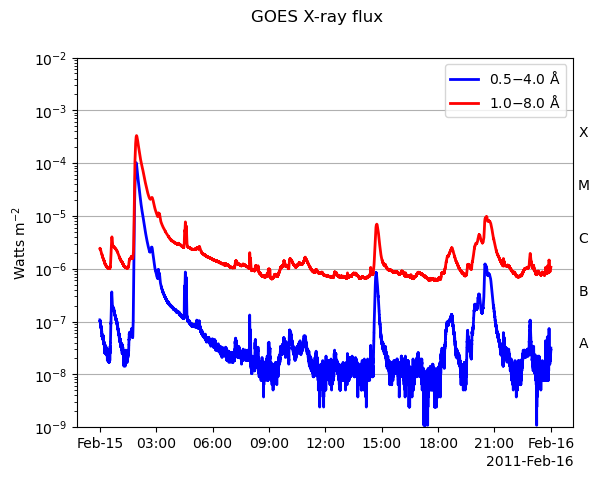

2011-02-16 01:39:00.000


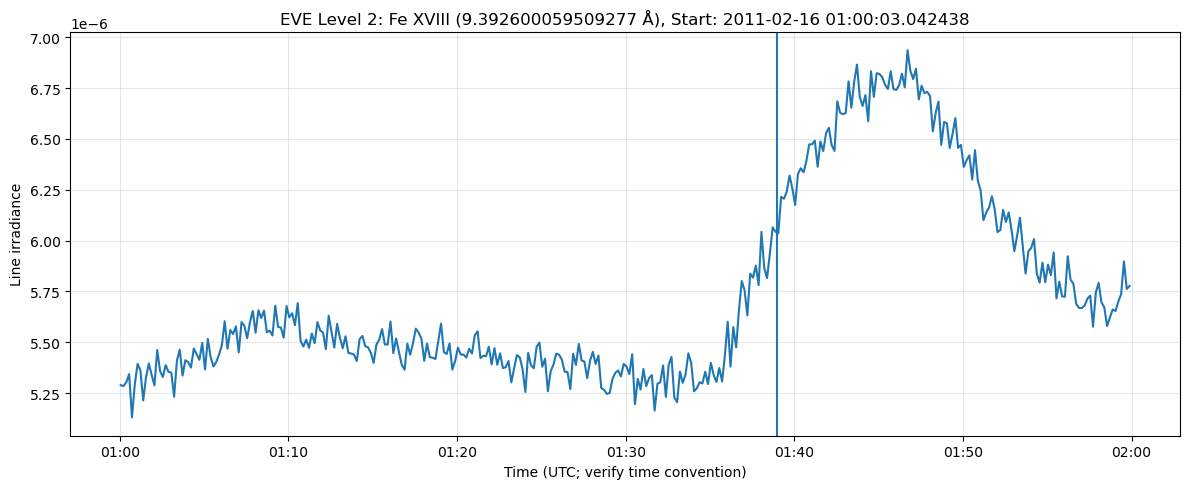

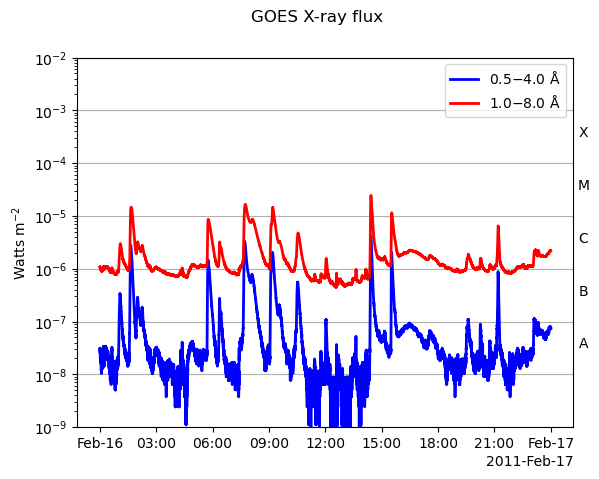

2011-02-16 07:44:00.000


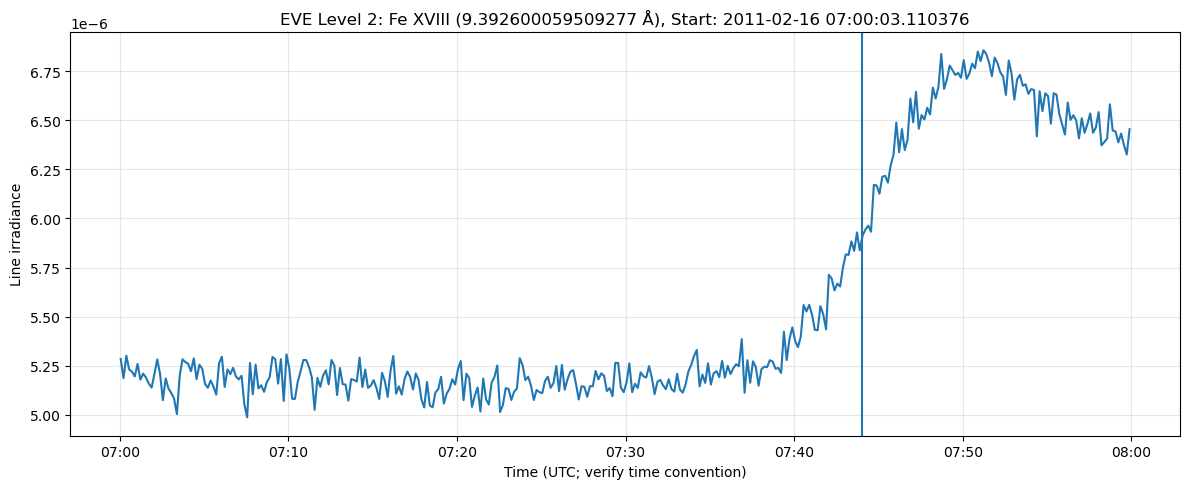

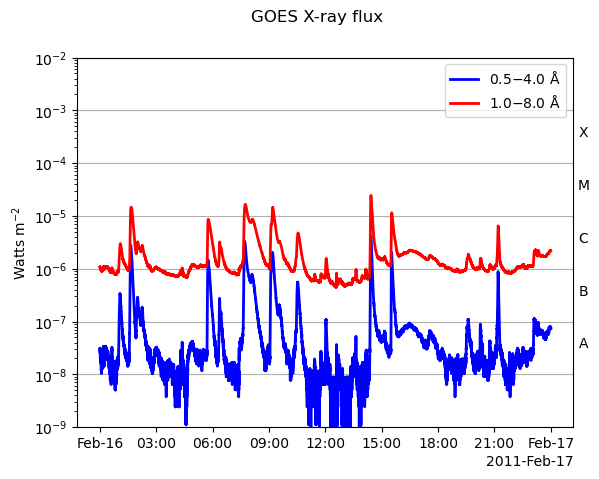

2011-02-16 14:25:00.000


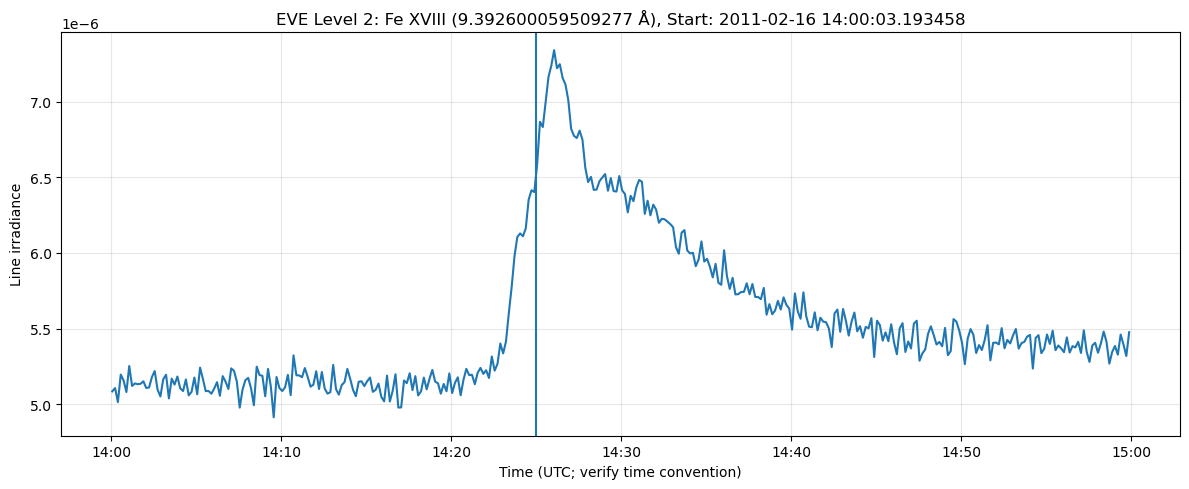

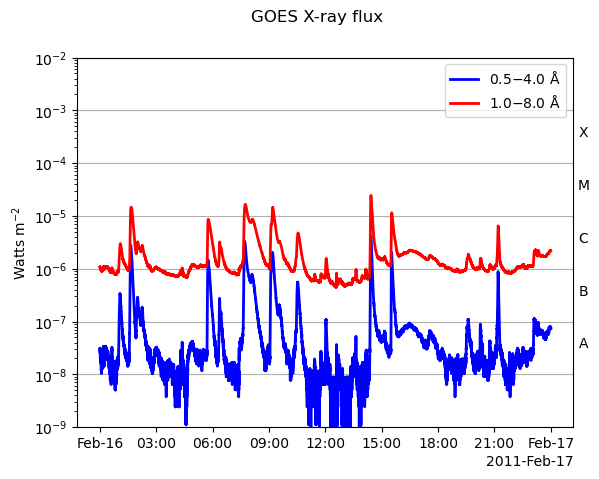

2011-02-18 10:00:00.000


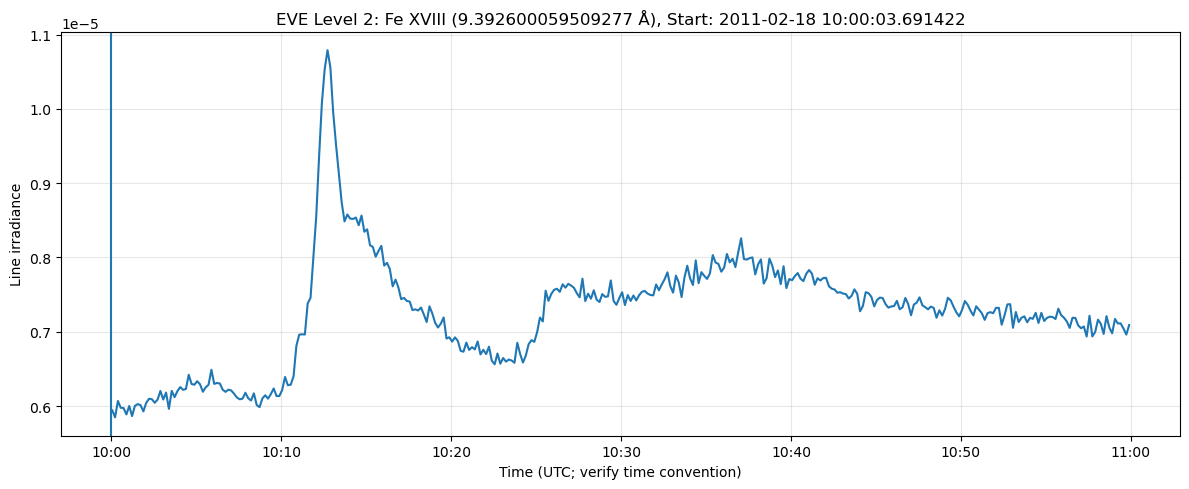

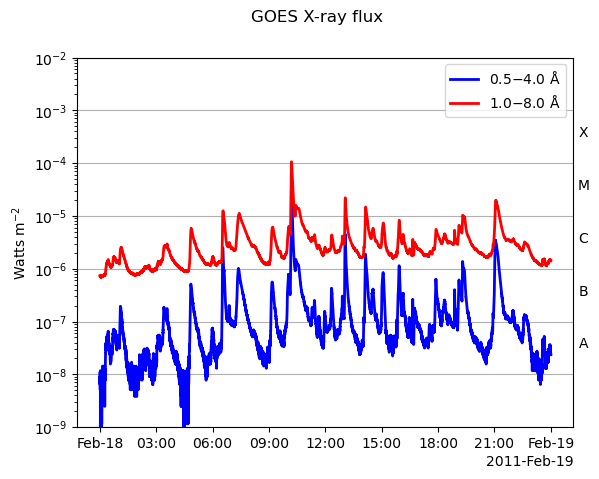

2011-02-18 13:03:00.000


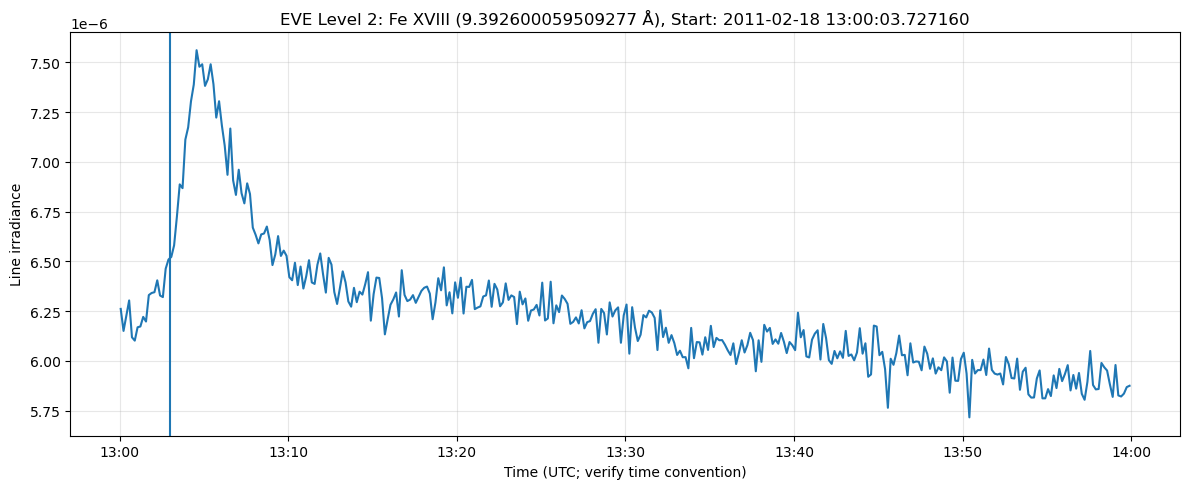

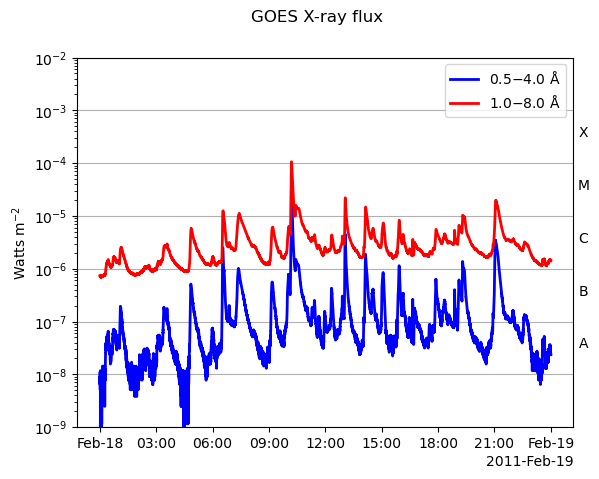

2011-02-18 14:08:00.000


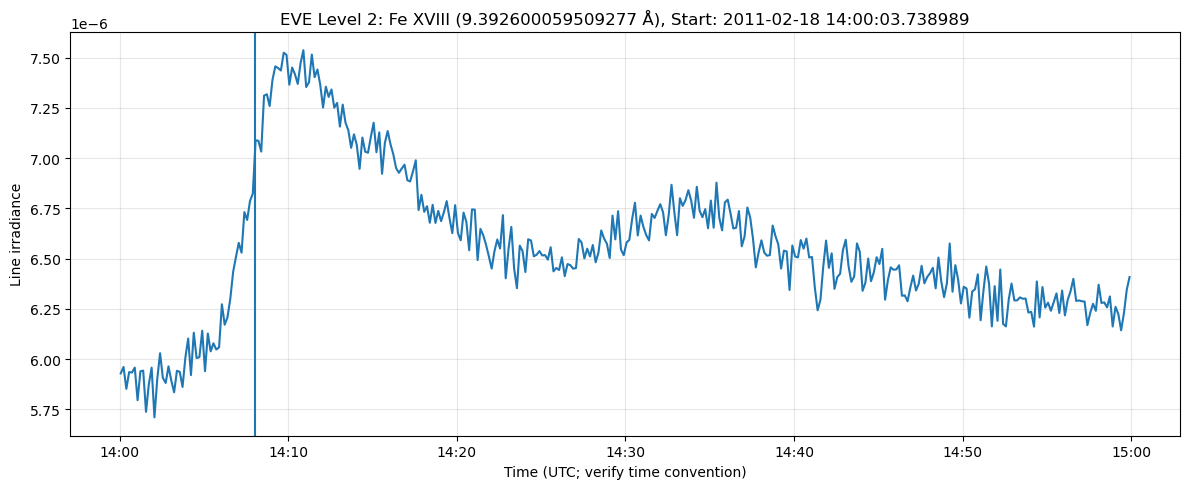

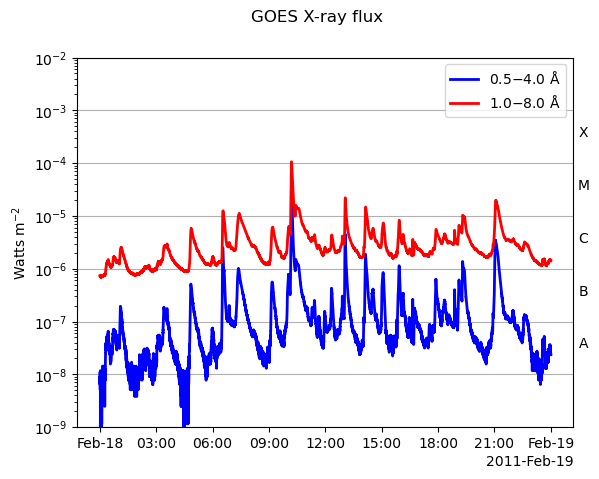

2011-02-18 21:04:00.000
2011-02-24 07:31:00.000
2011-02-28 12:45:00.000
2011-03-07 05:13:00.000


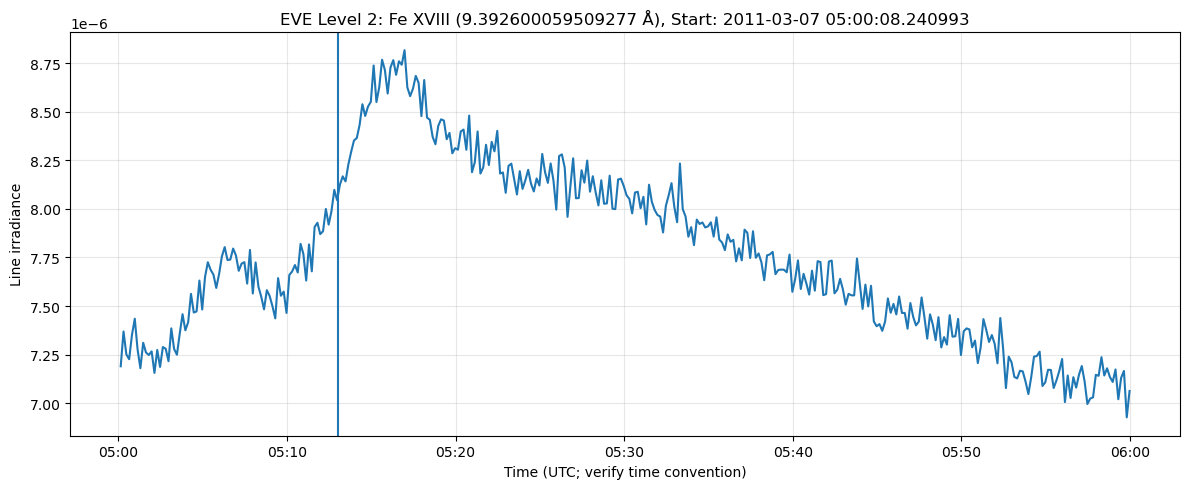

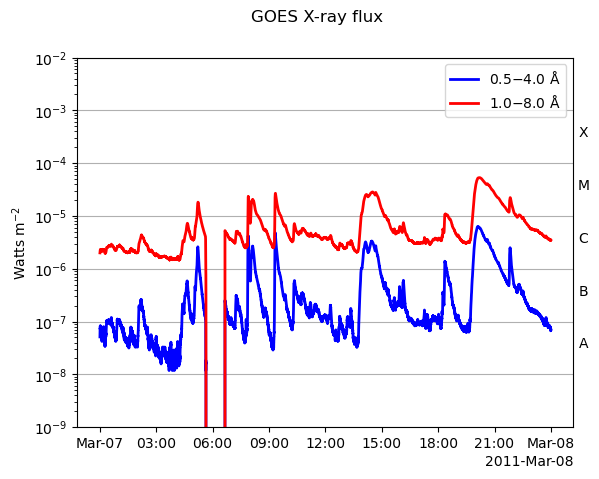

2011-03-07 07:54:00.000


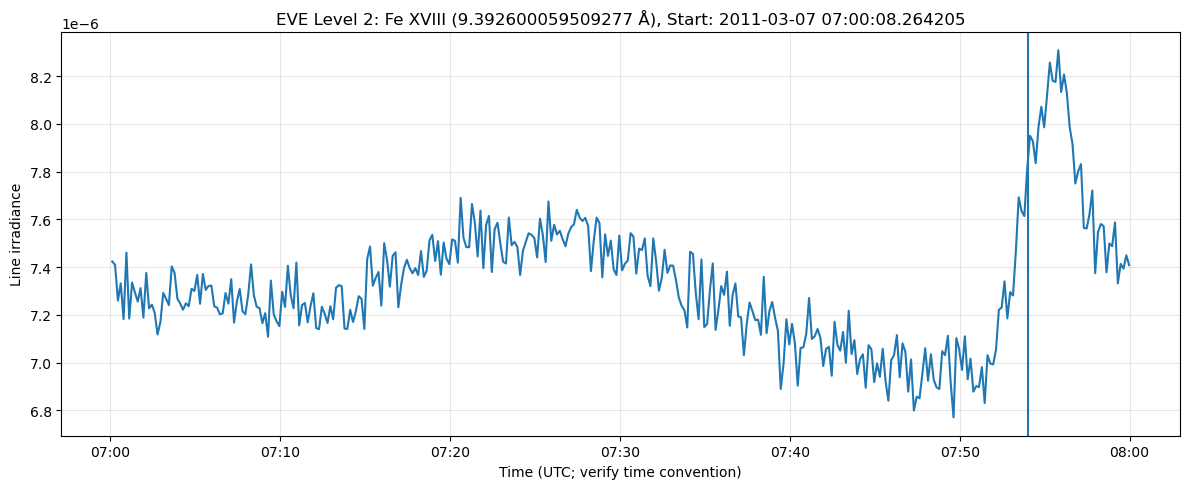

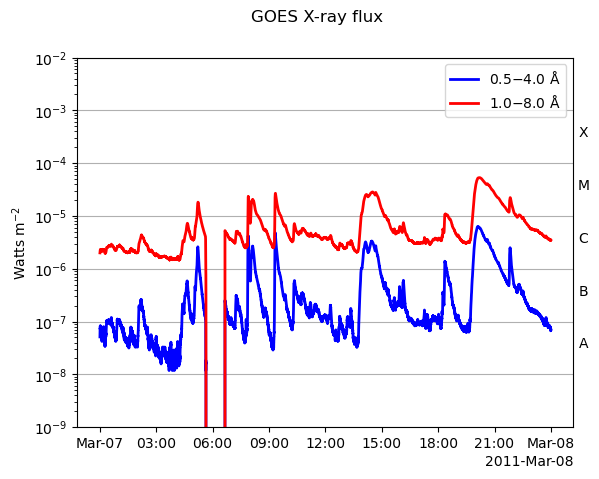

2011-03-07 08:07:00.000


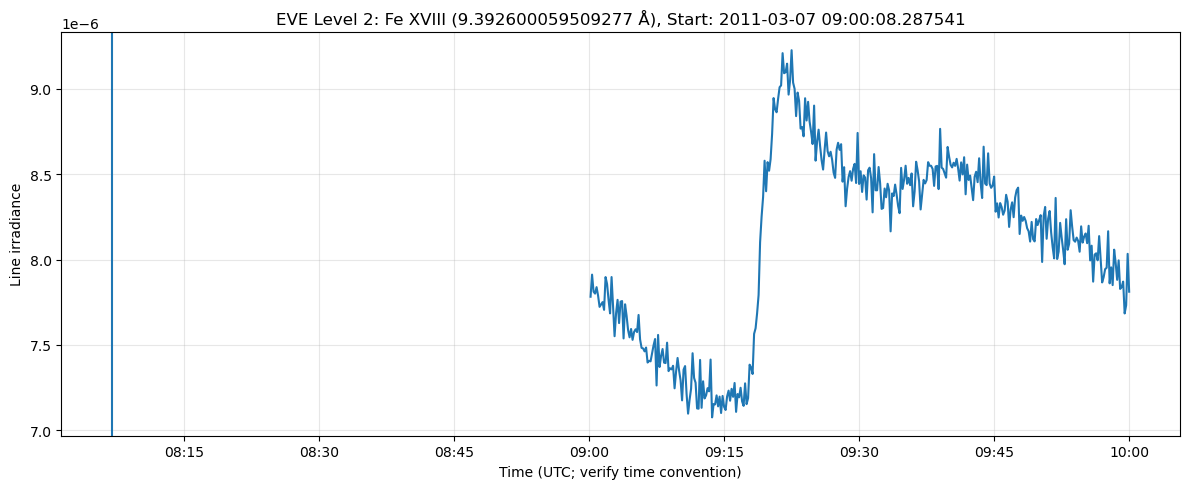

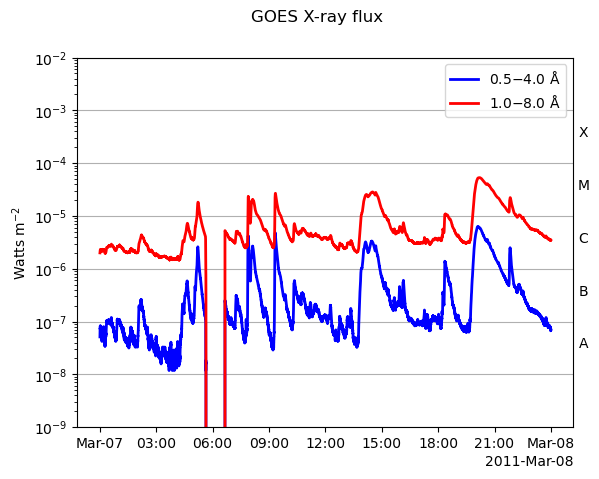

2011-03-07 09:15:00.000


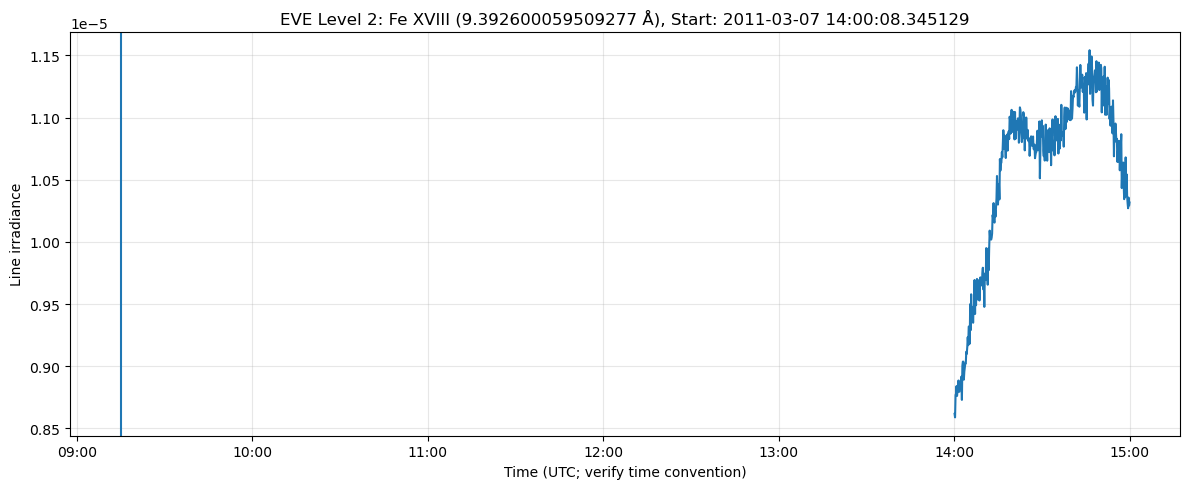

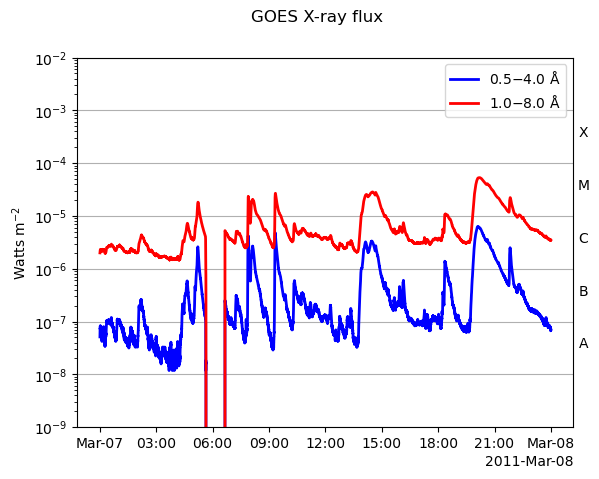

2011-03-07 14:00:00.000


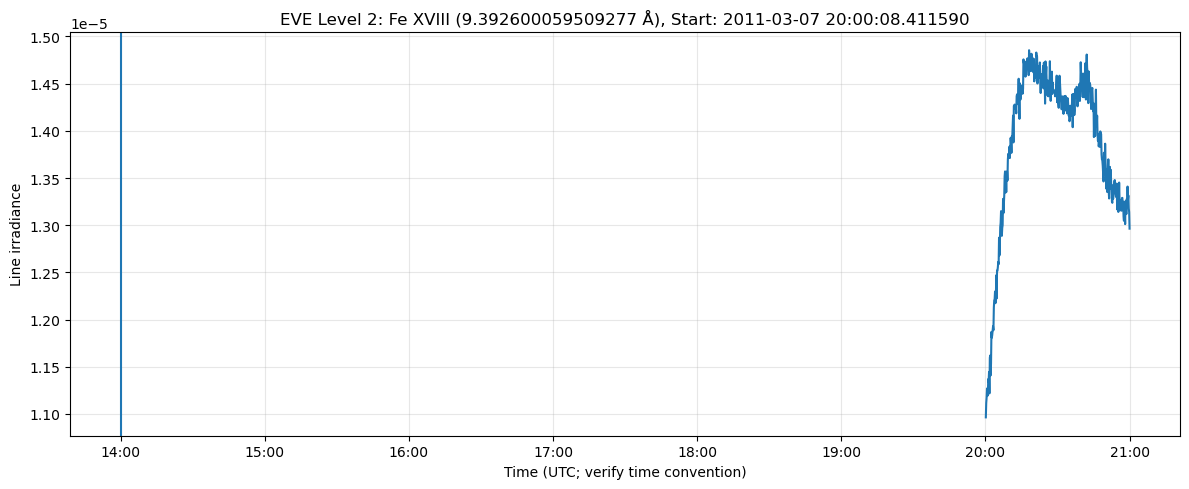

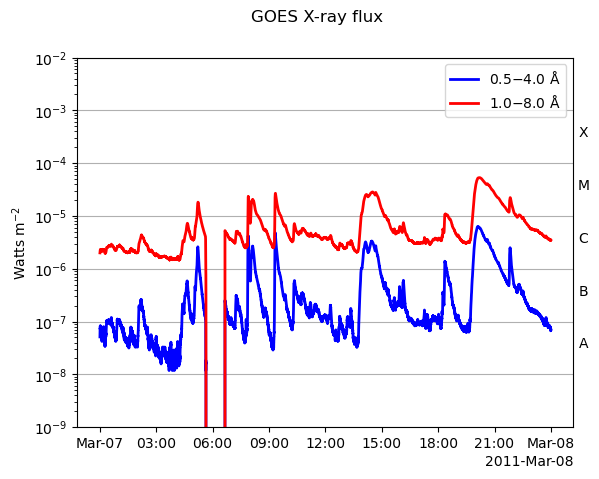

2011-03-07 20:01:00.000
2011-03-07 21:50:00.000


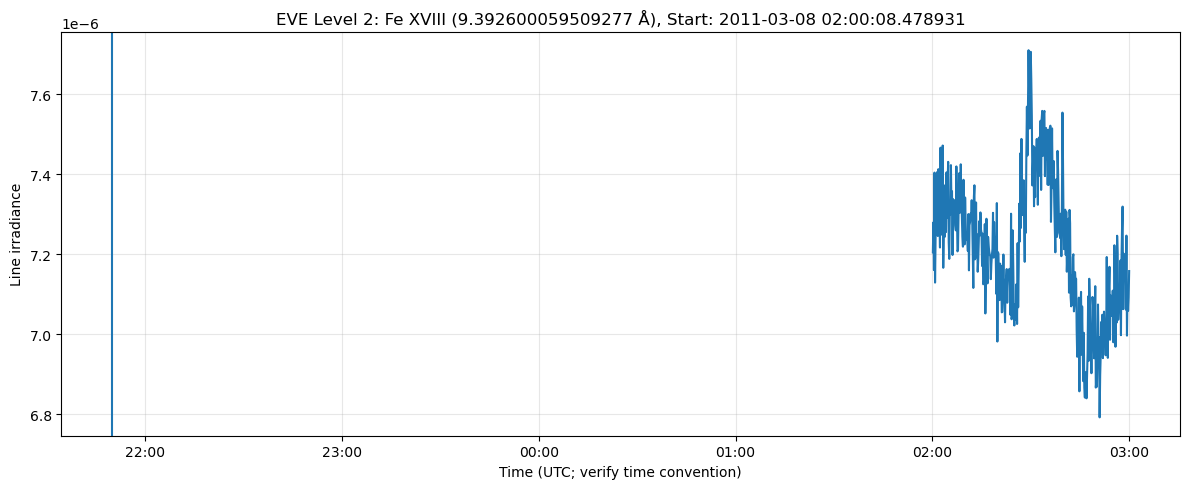

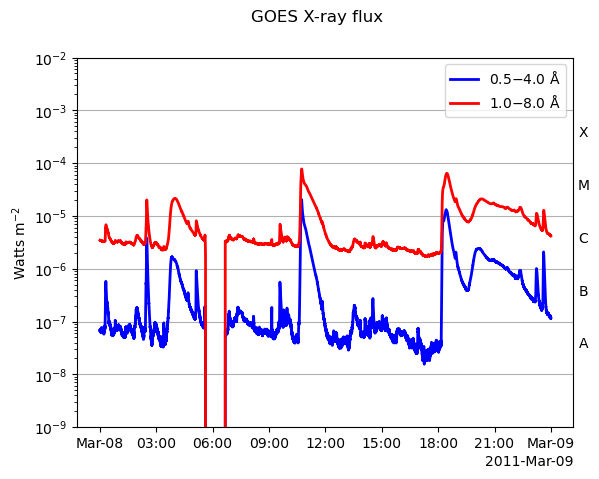

2011-03-08 02:29:00.000
2011-03-08 03:45:00.000


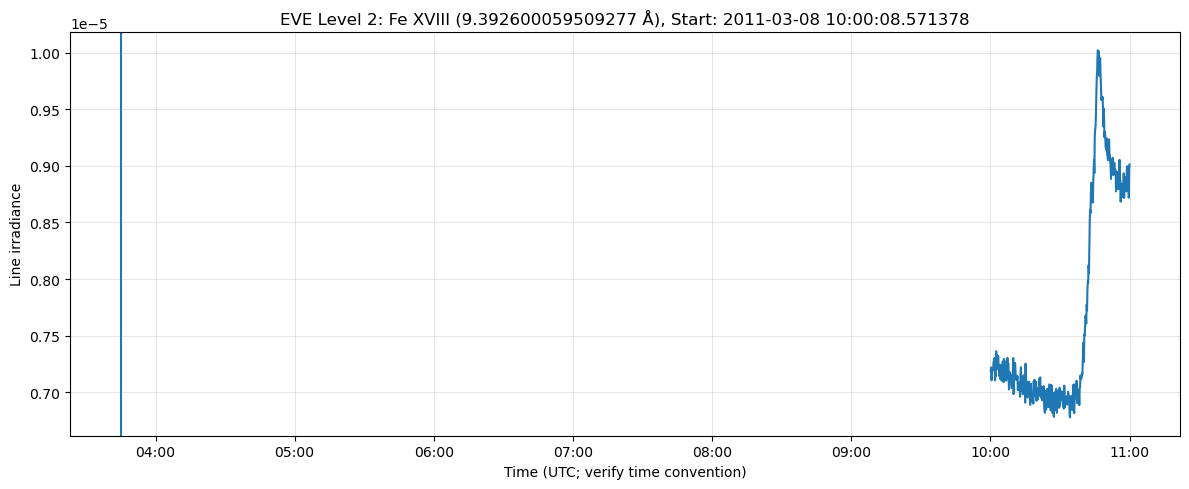

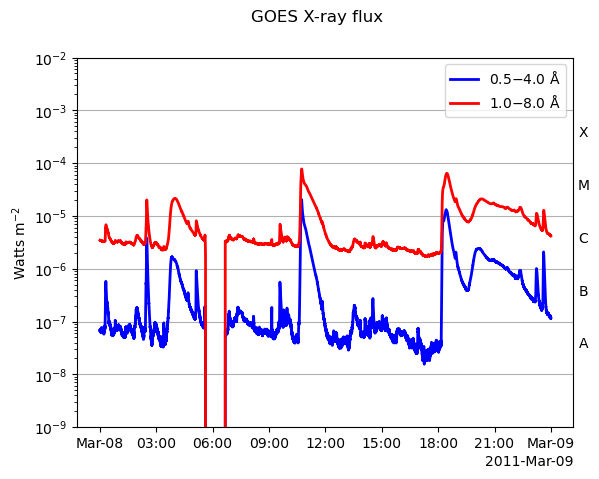

2011-03-08 10:44:00.000


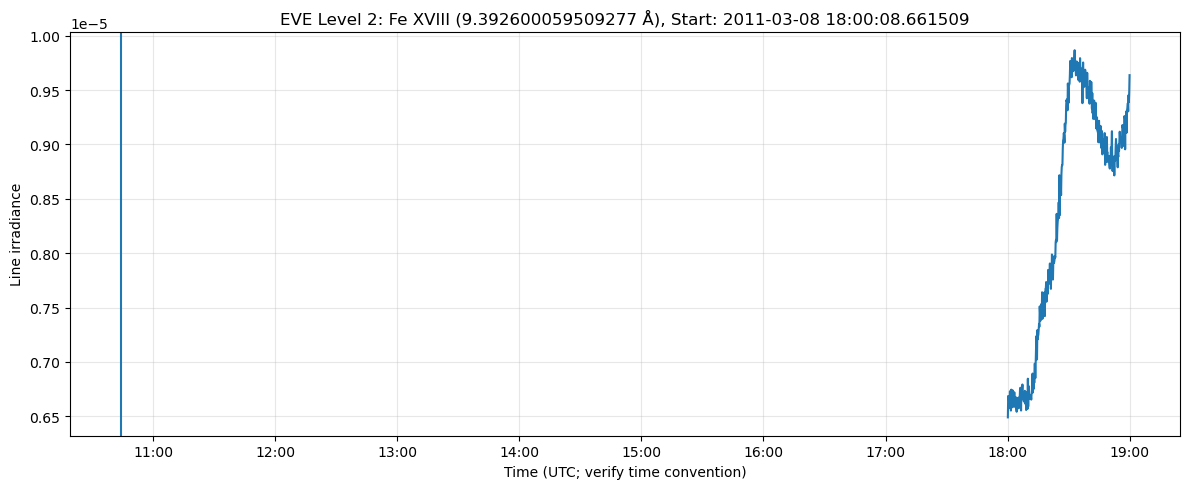

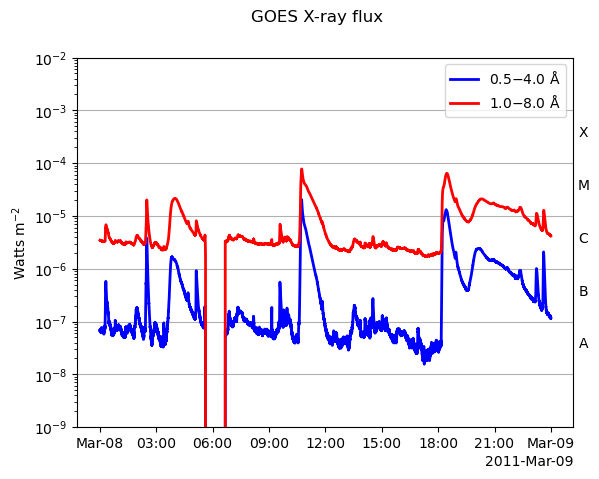

2011-03-08 18:28:00.000


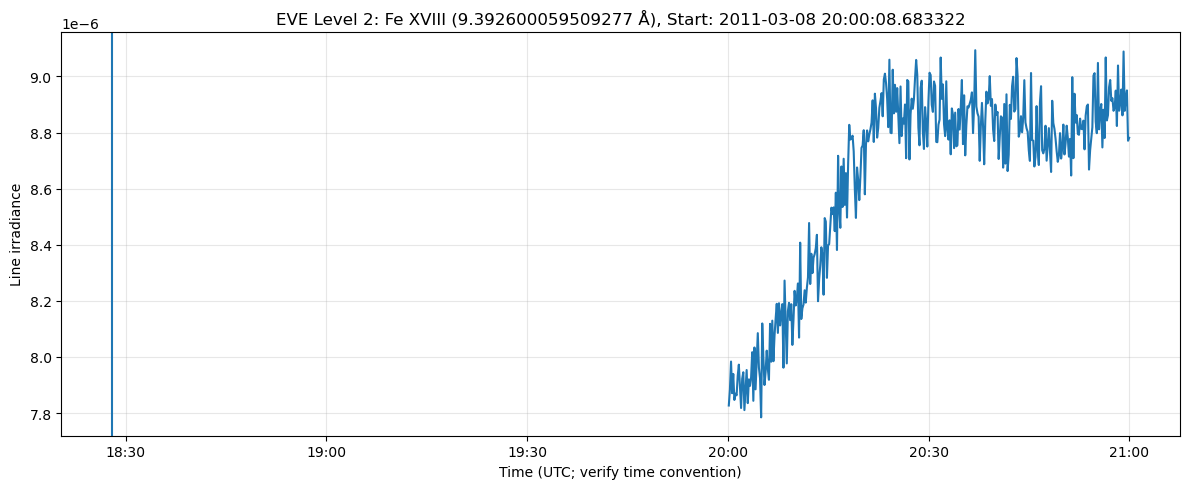

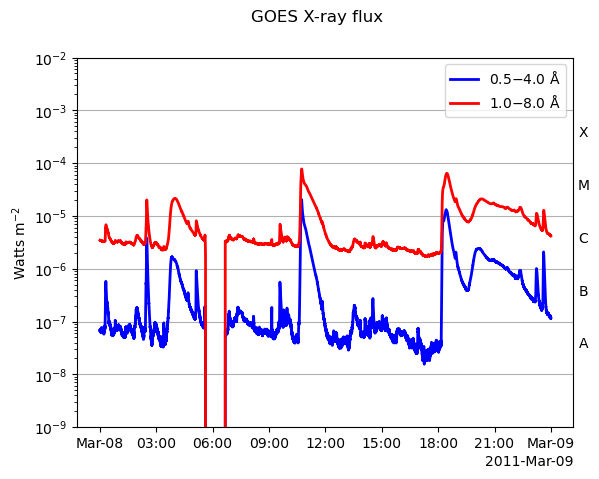

2011-03-08 20:16:00.000


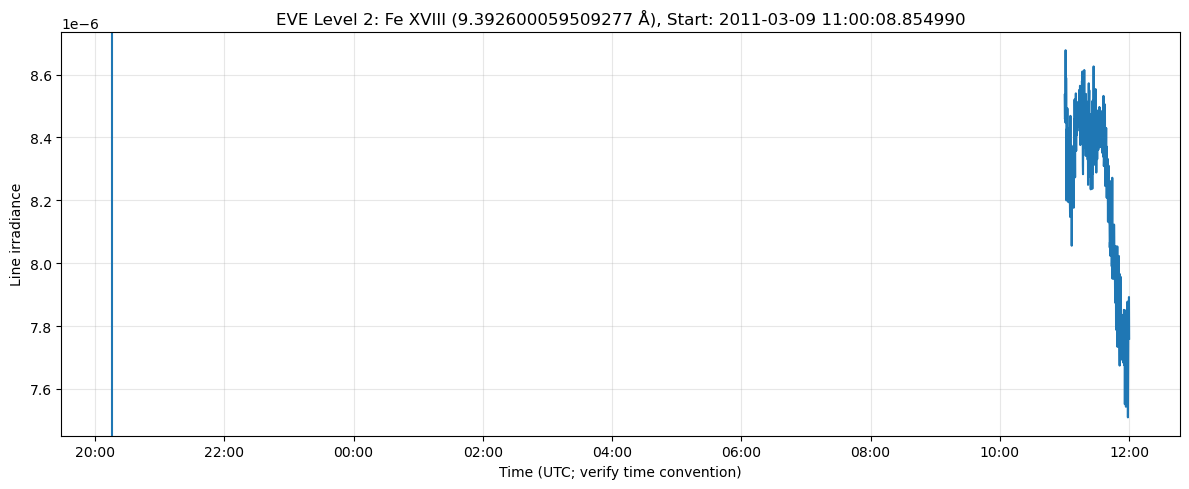

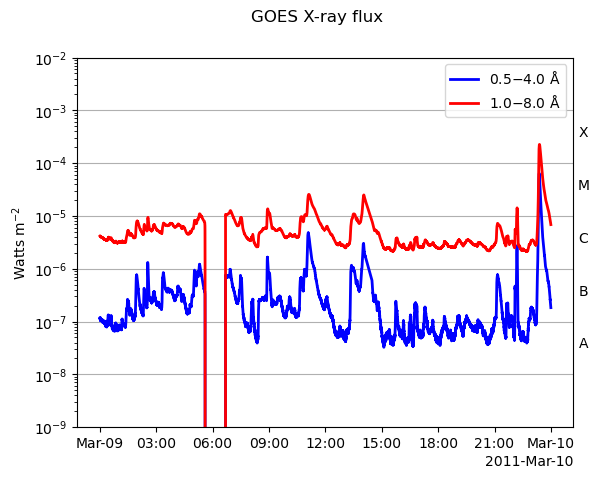

2011-03-09 11:07:00.000


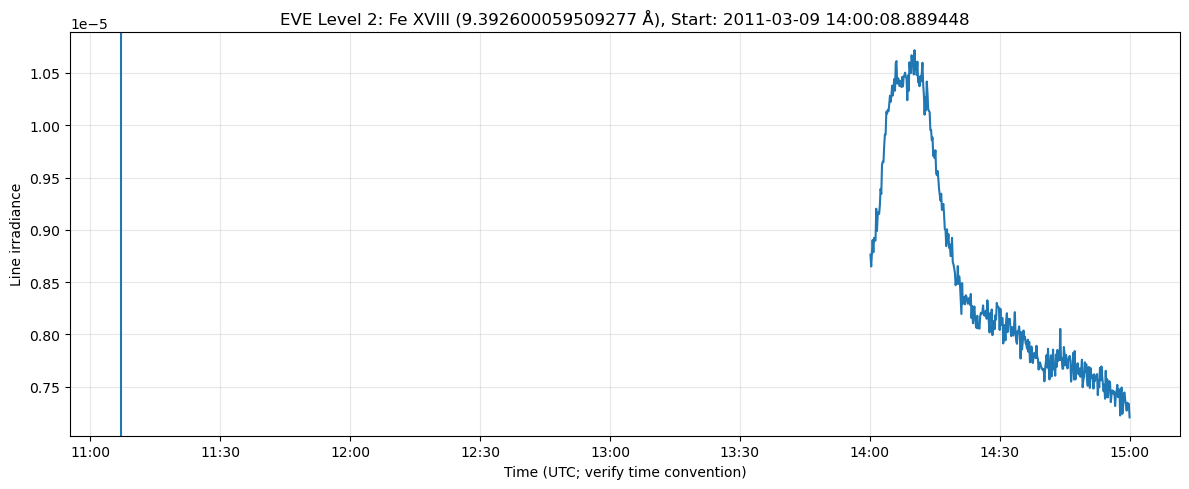

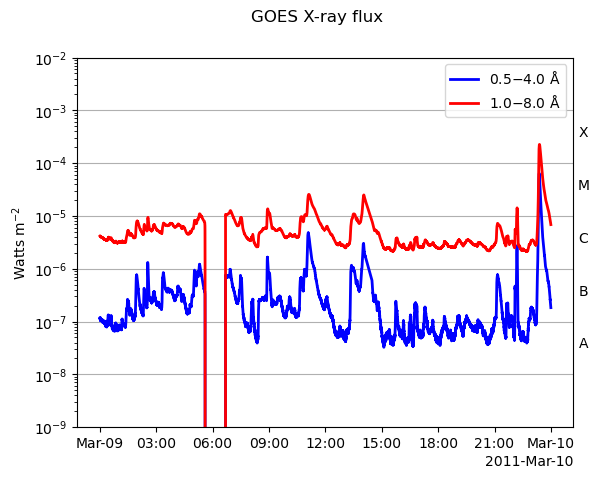

2011-03-09 14:02:00.000


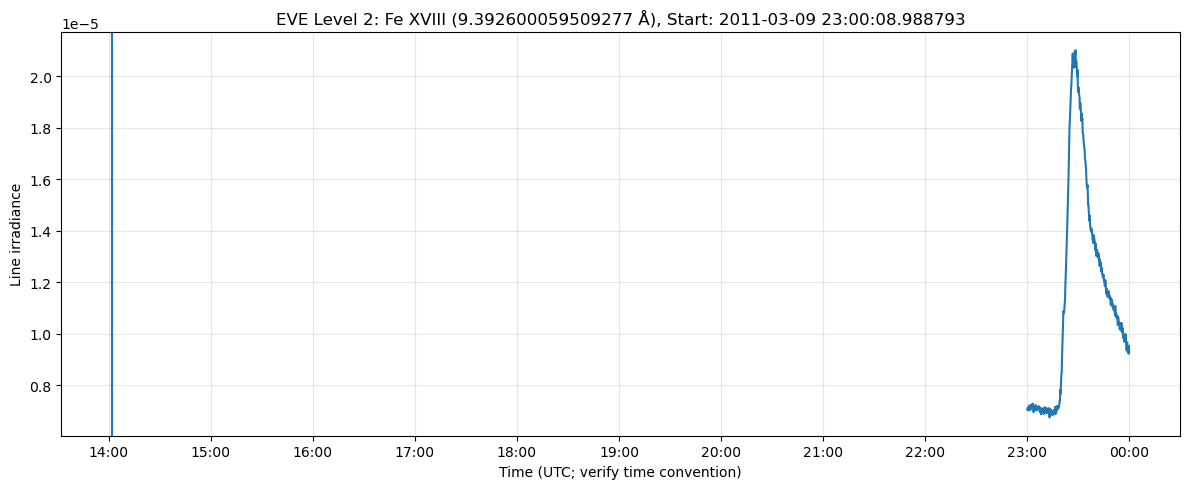

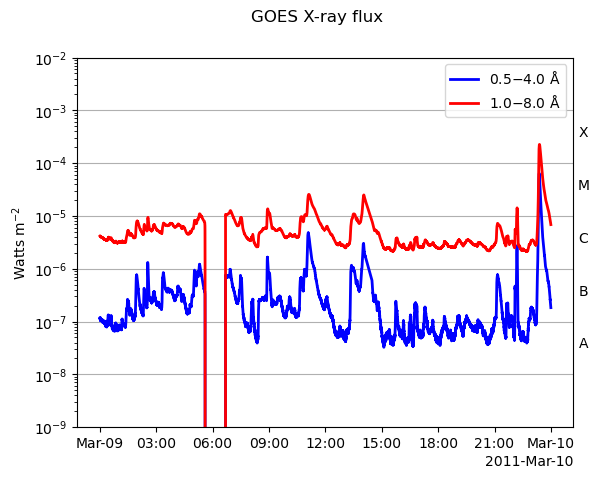

2011-03-09 23:16:00.000


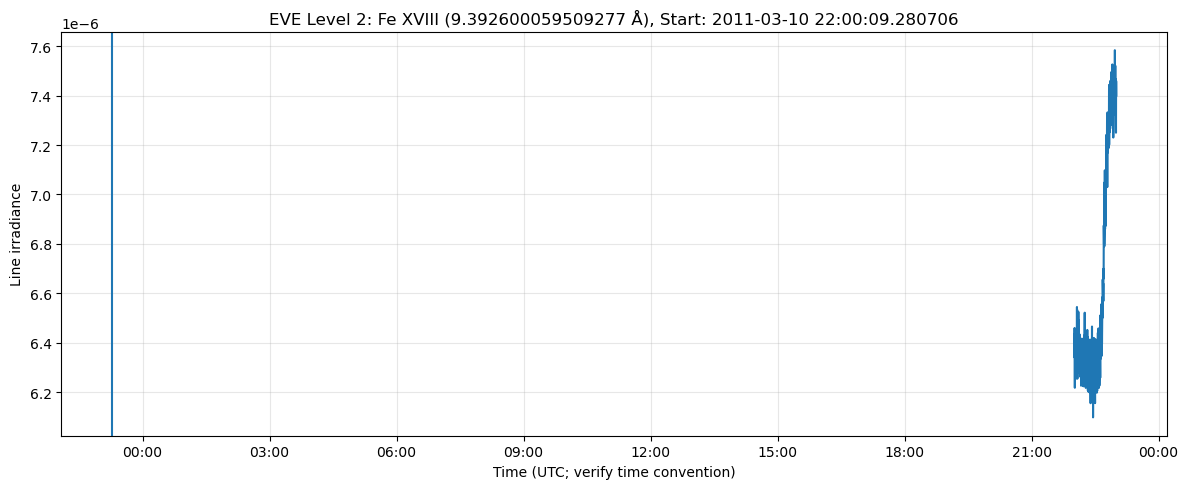

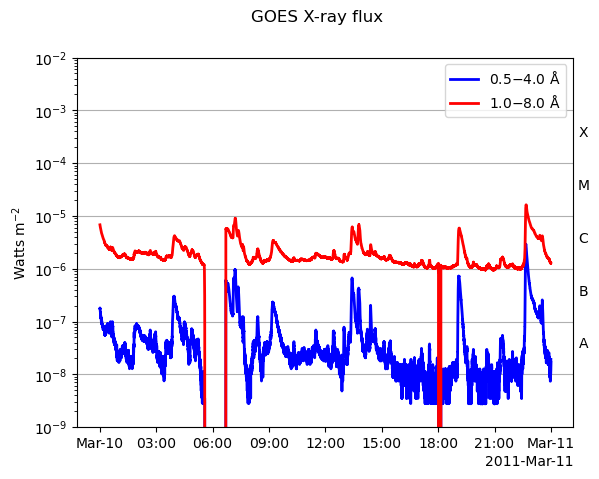

2011-03-10 22:41:00.000


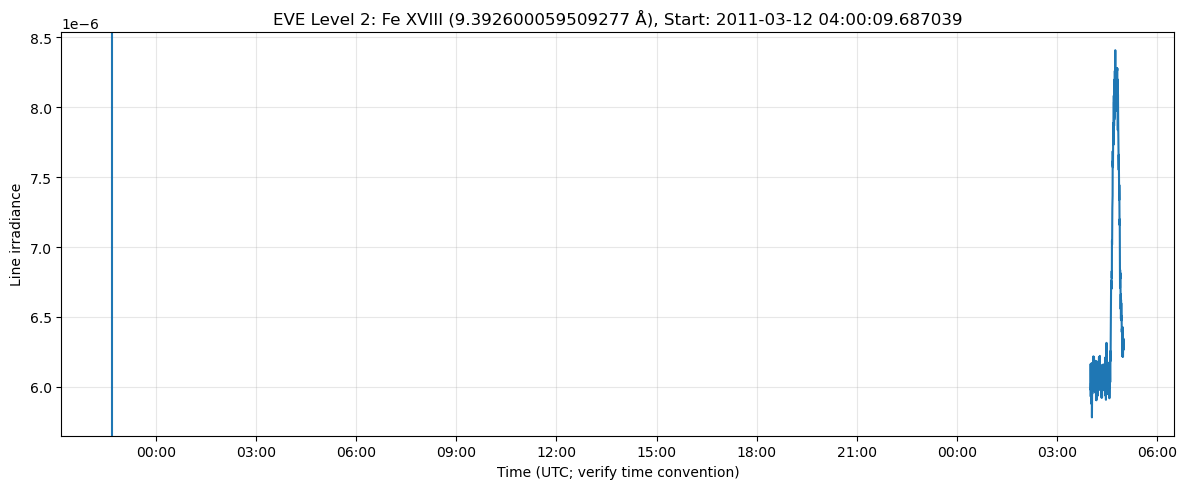

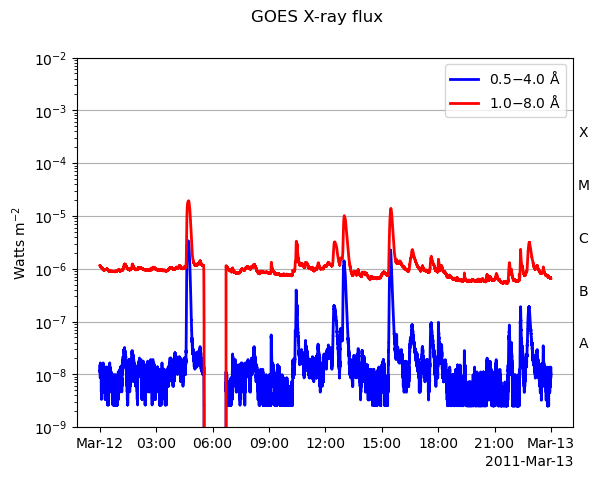

2011-03-12 04:43:00.000


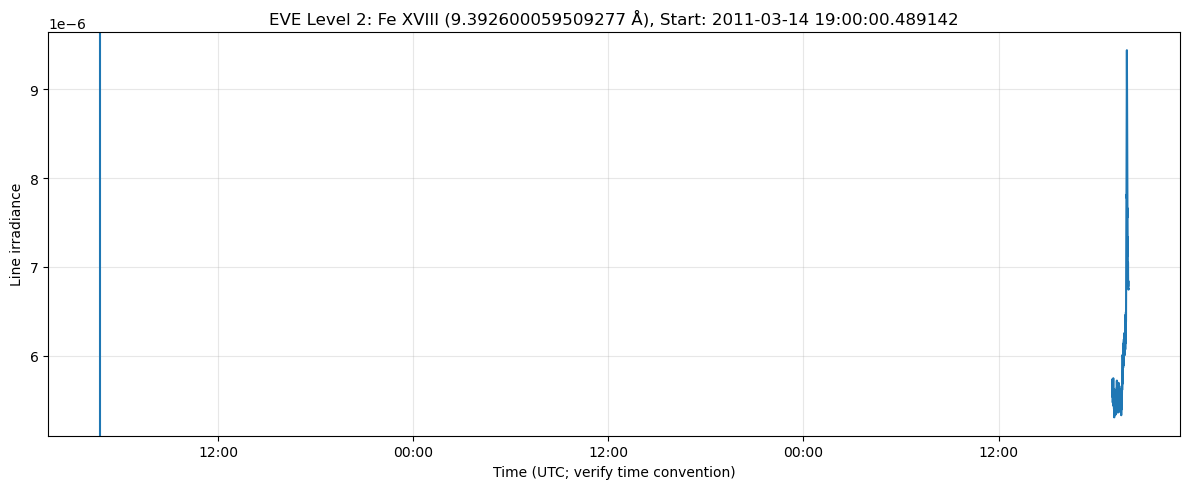

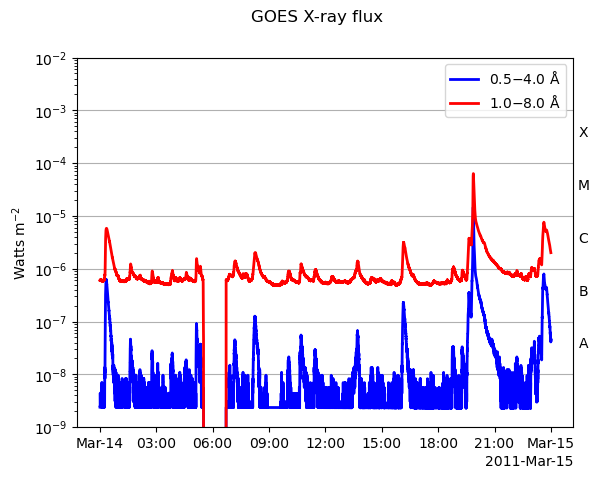

2011-03-14 19:38:00.000


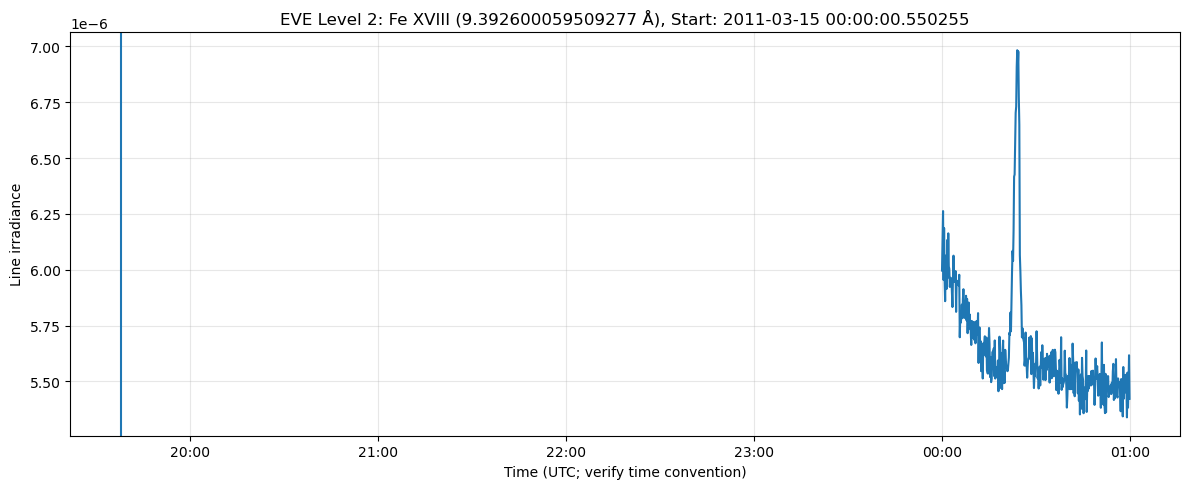

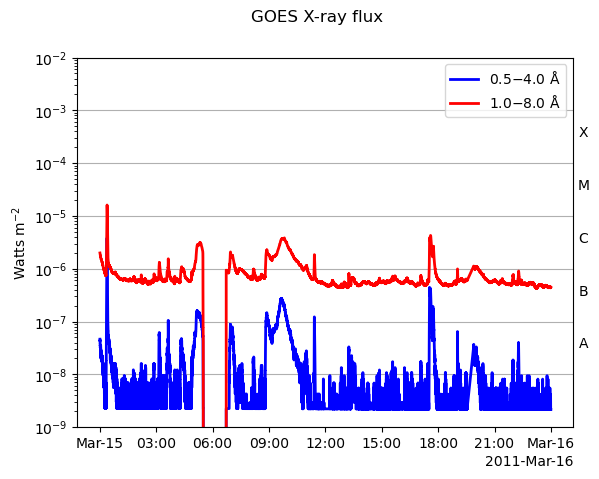

2011-03-15 00:22:00.000


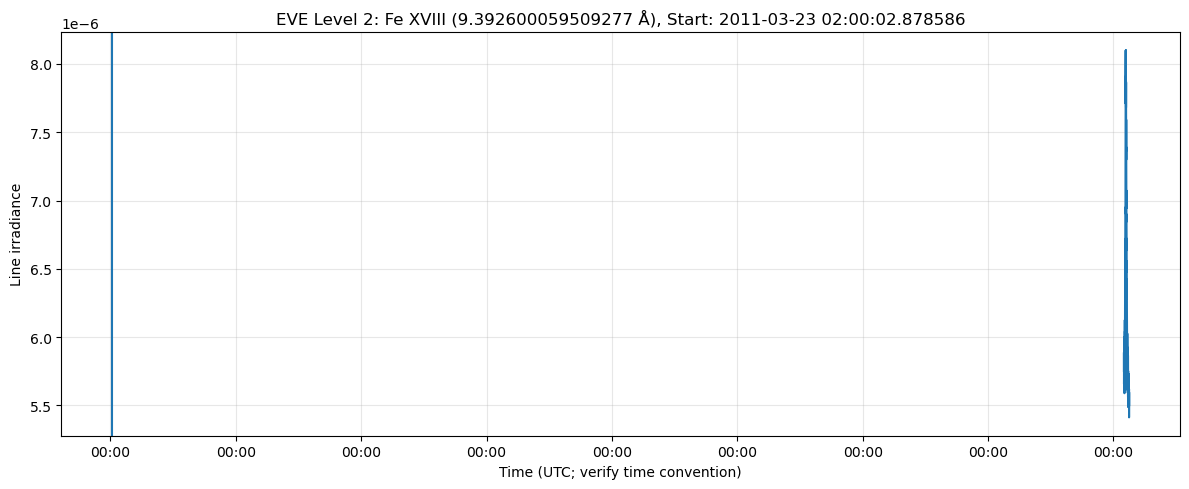

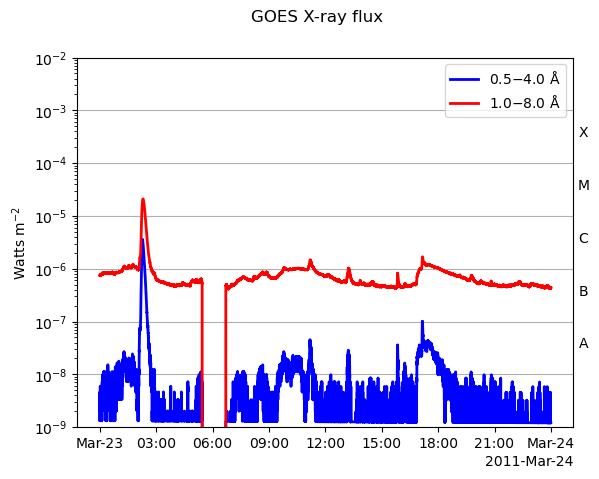

2011-03-23 02:17:00.000


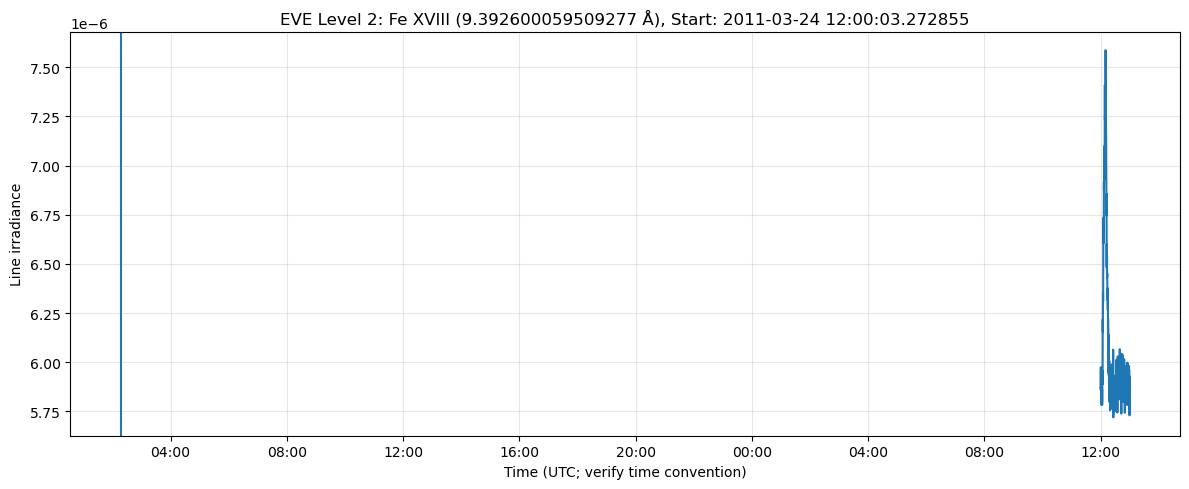

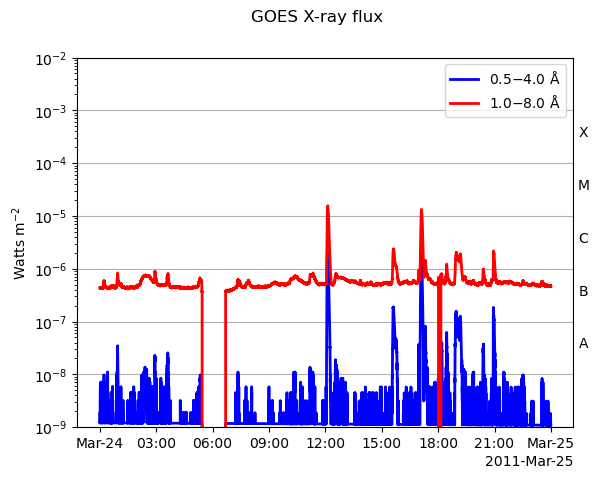

2011-03-24 12:07:00.000


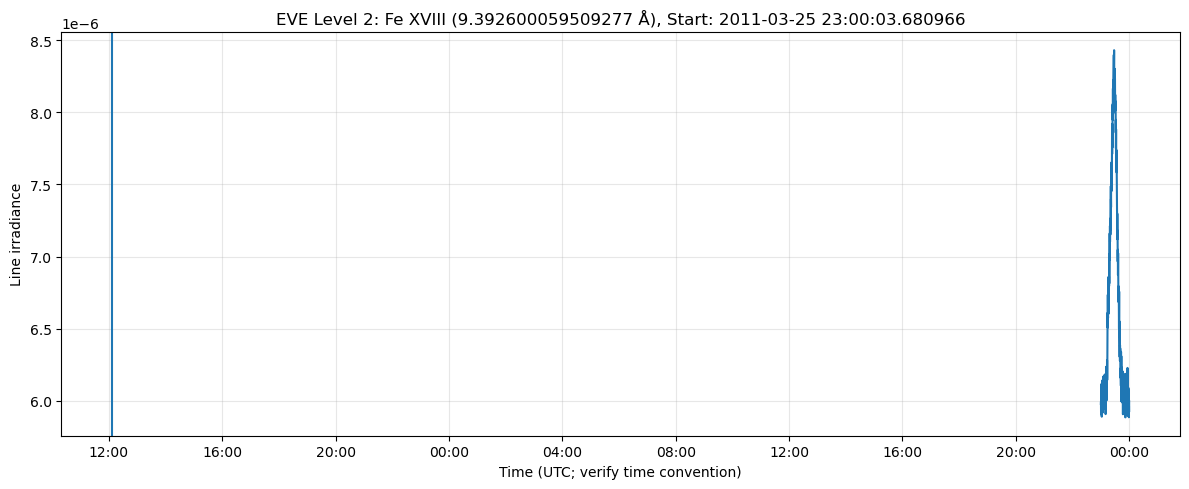

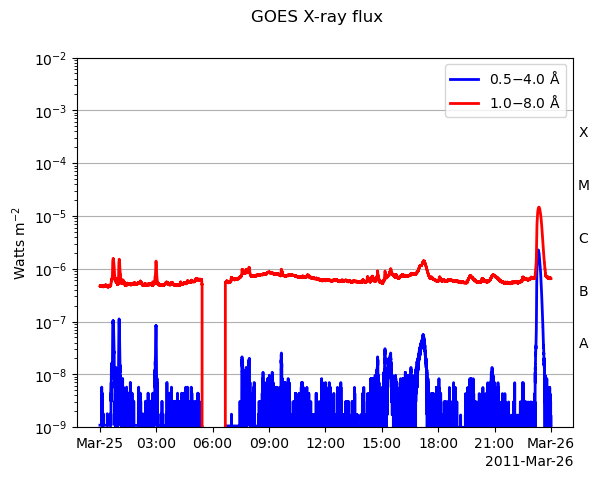

In [20]:
#filename = "EVL_L2_files/"+"EVL_L2_2010219_18_008_01.fit.gz"

files=filename

for k in range(len(files)):

    file = "EVL_L2_files/"+files[k]
    
    with fits.open(file) as hdul:
        data = hdul["LinesData"].data
        meta = hdul["LinesMeta"].data
    
        line_irradiance = np.asarray(data["LINE_IRRADIANCE"])
        year_doy = data["YYYYDOY"]
        sod = data["SOD"]
        #for i, line in enumerate(meta):
         #   print(i, line["NAME"], line["WAVE_CENTER"]) ##to see the emission lines
    
    # Convert YYYYDOY and SOD to datetime
    times = []
    for yd, seconds in zip(year_doy, sod):
        year = int(yd) // 1000
        doy = int(yd) % 1000
        dt = datetime(year, 1, 1) + timedelta(
            days=doy - 1, seconds=float(seconds)
        )
        times.append(dt)


                    
    ######################################################## getting the peak flare flux at event peak time 
    print(peak_time[k])
    o=0
    if o==1:
            start_time = "2010-06-21 08:00"
            end_time   = "2010-06-21 10:00" 
                            
            goes_range = goes.truncate(start_time, end_time)
            
            # GOES long-wavelength channel: 1–8 Å
            flux = goes_range.to_dataframe()["xrsb"]
            
            # Find peak flux and its time
            peak_time = flux.idxmax()
            peak_flux = flux.max()
            
            print(f"Peak time: {peak_time}")
            print(f"Peak flux: {peak_flux:.4e} W/m²")
    
    
    
    
        
    for i in range(1):
        # Choose an emission line
        line_index = i
    
        
        
        if (int(np.average(line_irradiance[:, line_index]))<0):
            continue
    

        if (int(np.min(line_irradiance[:, line_index]))<0):
            #print(line_irradiance[:, line_index]) #############################
            #plt.ylim(bottom=(0.9*max(line_irradiance[:, line_index])))
            continue
        
        
        
        
        
        plotting=1
        if plotting==1:
            plt.figure(figsize=(12, 5))
            plt.plot(times, line_irradiance[:, line_index])
            plt.xlabel("Time (UTC; verify time convention)")
            plt.ylabel("Line irradiance")
            plt.title(
                f"EVE Level 2: {meta[line_index]['NAME']} "
                f"({meta[line_index]['WAVE_CENTER']} Å)"
                f", Start: {times[0]}"
            )
            
            plt.axvline(peak_time[k].to_datetime())      # files are getting processed in random order 
            #plt.axvline(times[200])
            #print(mag_class[k])
            
            plt.gca().xaxis.set_major_formatter(
                mdates.DateFormatter("%H:%M")
            )
            plt.grid(True, alpha=0.3)
            plt.tight_layout()
            plt.show()
    
            goes_15 = ts.TimeSeries(Xrayfilename[k])
            goes_15.peek()

In [15]:
print(filename)
print(peak_time)

['EVL_L2_2010125_17_008_01.fit.gz', 'EVL_L2_2010163_00_008_01.fit.gz', 'EVL_L2_2010164_05_008_01.fit.gz', 'EVL_L2_2010219_18_008_01.fit.gz', 'EVL_L2_2010289_19_008_01.fit.gz', 'EVL_L2_2010308_23_008_01.fit.gz', 'EVL_L2_2010309_13_008_01.fit.gz', 'EVL_L2_2010310_15_008_01.fit.gz', 'EVL_L2_2011028_01_008_01.fit.gz', 'EVL_L2_2011040_01_008_01.fit.gz', 'EVL_L2_2011044_17_008_01.fit.gz', 'EVL_L2_2011045_17_008_01.fit.gz', 'EVL_L2_2011046_01_008_01.fit.gz', 'EVL_L2_2011047_01_008_01.fit.gz', 'EVL_L2_2011047_07_008_01.fit.gz', 'EVL_L2_2011047_14_008_01.fit.gz', 'EVL_L2_2011049_10_008_01.fit.gz', 'EVL_L2_2011049_13_008_01.fit.gz', 'EVL_L2_2011049_14_008_01.fit.gz', 'EVL_L2_2011049_21_008_01.fit.gz', 'EVL_L2_2011055_07_008_01.fit.gz', 'EVL_L2_2011059_12_008_01.fit.gz', 'EVL_L2_2011066_05_008_01.fit.gz', 'EVL_L2_2011066_07_008_01.fit.gz', 'EVL_L2_2011066_09_008_01.fit.gz', 'EVL_L2_2011066_14_008_01.fit.gz', 'EVL_L2_2011066_20_008_01.fit.gz', 'EVL_L2_2011066_21_008_01.fit.gz', 'EVL_L2_2011067_02_